# WildSpeech V3 — Speech-Model Installation, Child ASR, Phonetic Intelligence & Reading Prediction (P23–P29)

**Question.** Do children's actual pronunciations, phoneme errors, speech confidence and acoustic representations predict
end-of-year reading outcomes *beyond* the screening scores (strongest tabular GAM `B_GAM__SCREENING+BEHAVIOR+ITEM`, R² ≈ 0.2153)?

**Models** (`configs/v3_asr_models.yaml`, schema 3, pinned commits + sha256 manifests): pasketti_phonetic (WavLM-CTC, IPA) ·
whisper_small_en · pasketti_word (Qwen3-ASR via qwen_asr + vLLM, WSL2/Linux only — *not* Whisper) · wav2vec2_phoneme_espeak ·
wav2vec2_base_960h · frozen encoders wav2vec2_base · hubert_base · wavlm_base_plus.

**Steps are kept apart — none of them implies the next:**

| step | what it means | where |
|---|---|---|
| planning | the orchestrator *would* run a stage (`PLANNED`) — nothing executed | §0 |
| reviews | a named human approved / rejected / deferred license, provenance, overlap | §2, terminal |
| download authorization | reviews pass **and** `ALLOW_MODEL_DOWNLOADS` (+ optional `DOWNLOAD_MODELS`) | §3 |
| installation | every manifest file at the pinned commit (sha256-verified, `.bin` → safetensors) | §3 |
| technical load | weights load + forward pass on **synthetic** audio (no review needed, no competition data) | §4 |
| smoke validation | a few training clips decode to non-empty, finite output (eligible models only) | §4 |
| inference | P24 writes accepted outputs (provenance `producer=P24`, eligible record) | §5 |
| completed artefacts | a stage whose status is `completed` **and** not `NOT_EXECUTED` | every section |

Saved tables are shown with an explicit state: `MISSING`, `NO_RESULTS` (an empty result — never a pandas crash), `STALE`
(left over from an earlier run of that stage; hidden), or current.

**Pasketti caution.** Both Pasketti cards list *ReadNet* (Reach Every Reader data) among their training corpora. This competition's
audio comes from the Reach Every Reader screener, so overlap is likely. Nothing in this notebook approves Pasketti; you accept it with
a written mitigation, reject it, or document it as deferred (§2).

## 0. Configuration (guarded defaults: explicitly opt into inference and downloads)


In [1]:
# ===== central control =====
RUN_PIPELINE = False            # True = actually execute the stage cells (GPU inference, repeated CV)
ALLOW_MODEL_DOWNLOADS = False   # True = install models whose reviews ALL pass (pinned commit, sha256-verified)
RUN_SMOKE = False               # True = technical load check (synthetic audio) + few-clip smoke decode of eligible models
FORCE = False                   # True = recompute every stage a cell requests (protected P23 excluded)
FORCE_STAGES = []               # explicit list, e.g. ["P24"]; the ONLY way to recompute the protected P23: ["P23"]
DOWNLOAD_MODELS = []            # [] = every approved model; else only these keys, e.g. ["wav2vec2_base_960h"]
PROFILE = "V3_FULL"             # V3_SMOKE | V3_AUDIT | V3_ASR | V3_SCIENCE | V3_FULL | V3_SUBMISSION
DEEP_CHECK = False               # instantiate processors / tokenizers of installed snapshots (no weights)
VERIFY_HASHES = False           # sha256 every installed weight file now (cached afterwards)
OVERRIDES = {
    # "v3": {"asr": {"max_clips": 500}},                                  # quick pass
    # "v3": {"asr": {"models": ["whisper_small_en", "wav2vec2_base_960h"]}},
    # "v3": {"runtime": {"max_repeats": 1}},                              # first CV repeat only
}
dl = OVERRIDES.setdefault("v3", {}).setdefault("asr", {}).setdefault("downloads", {})
if ALLOW_MODEL_DOWNLOADS:
    dl["allow_model_downloads"] = True
if DOWNLOAD_MODELS:
    dl["authorized_models"] = list(DOWNLOAD_MODELS)
FORCE_ARG = True if FORCE is True else list(FORCE_STAGES)

import sys
from pathlib import Path

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(REPO / "src") not in sys.path:
    sys.path.insert(0, str(REPO / "src"))

import pandas as pd
from IPython.display import display, Markdown
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)

from wildspeech.v3 import notebook as nb

ctx = nb.context(PROFILE, OVERRIDES)
print("profile:", ctx.profile, "| device:", ctx.device, "| data:", ctx.paths.data_dir)
print("outputs:", ctx.paths.v3_root, "| caches:", ctx.paths.v3_cache)
print(f"RUN_PIPELINE={RUN_PIPELINE} ALLOW_MODEL_DOWNLOADS={ALLOW_MODEL_DOWNLOADS} RUN_SMOKE={RUN_SMOKE} FORCE={FORCE_ARG}")
# An eligible model must also have evidence-backed review approval.
# Do not change this through inference or checkpoint installation.
print("SAFE MODE: no downloads, model execution, or forced recomputation by default")


13:47:48 | INFO    | context: profile=V3_FULL device=cuda root=C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU data=C:\Users\myben\Downloads\WildSpeech_P01\data


profile: V3_FULL | device: cuda | data: C:\Users\myben\Downloads\WildSpeech_P01\data
outputs: C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\outputs\V3 | caches: C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\cache\v3
RUN_PIPELINE=False ALLOW_MODEL_DOWNLOADS=False RUN_SMOKE=False FORCE=[]
SAFE MODE: no downloads, model execution, or forced recomputation by default


In [2]:
# ===== Safe result display and explicit run gates =====
from pandas.errors import EmptyDataError

def safe_table(stage, name, **kwargs):
    try:
        value = nb.table(ctx, stage, name, **kwargs)
        if value is None or (isinstance(value, pd.DataFrame) and value.empty):
            print(f"[{stage}/{name}] NO_RESULTS")
            return None
        return value
    except (EmptyDataError, FileNotFoundError, IsADirectoryError, pd.errors.ParserError) as exc:
        print(f"[{stage}/{name}] NO_RESULTS: {type(exc).__name__}: {exc}")
        return None

def safe_tables(stage, names):
    for name in names:
        value = safe_table(stage, name, n=None)
        if value is not None:
            print(f"[{stage}/{name}]")
            display(value.head(30) if isinstance(value, pd.DataFrame) else value)

def accepted_asr_models():
    """Require a real inference outcome, not simply stage completion."""
    try:
        o = nb.p24_outcome(ctx) or {}
        names = o.get("accepted_models") or []
        if not bool(o.get("inference_executed", False)):
            return []
        return list(names)
    except (KeyError, FileNotFoundError, ValueError, TypeError):
        return []

def run_when_ready(stage, minimum_models=1):
    accepted = accepted_asr_models()
    if not RUN_PIPELINE:
        print(f"[{stage}] PLANNED; RUN_PIPELINE=False")
        return
    if len(accepted) < minimum_models:
        print(f"[{stage}] BLOCKED_DEPENDENCY: requires {minimum_models} executed, accepted ASR model(s); found {len(accepted)}")
        return
    display(nb.run_stages(ctx, [stage], FORCE_ARG, enabled=True))

print("Execution gates initialized; no models or tests have run.")


Execution gates initialized; no models or tests have run.


In [3]:
# Reference numbers are READ from saved artefacts (never hard-coded); empty files print NO_RESULTS
b = ctx.bundle()
print(f"train students={len(b.train)}  train clips={len(b.train_clips)}  test students={len(b.test_students)}")
p10 = nb.table(ctx, "P10", "model_benchmark", n=None, allow_stale=True)
if p10 is not None and "r2_mean" in p10:
    display(p10.sort_values("r2_mean", ascending=False)[[c for c in ("name", "model", "families", "r2_mean", "r2_sd") if c in p10]].head(5))
p17 = nb.table(ctx, "P17", "clip_metrics", n=None, allow_stale=True)
if p17 is not None and "auroc" in p17:
    display(p17.sort_values("auroc", ascending=False).head(5))
p21 = nb.table(ctx, "P21", "all_results", n=None, allow_stale=True)
if p21 is not None and "delta_r2" in p21:
    print(f"V2 P21: {int((p21['delta_r2'] == 0).sum())} of {len(p21)} rows report ΔR² exactly 0 -> audited in P23")
display(nb.status(ctx))
print("--- V3 stage readiness (results_are_real = completed AND not NOT_EXECUTED)")
display(nb.stage_readiness(ctx))

13:47:48 | INFO    | data: train 541 students / 14704 clips, test 361 / 9814, tasks=['blending', 'deletion', 'sentence_repetition'], thetas=['blending_theta', 'deletion_theta', 'sentence_repetition_theta']


train students=541  train clips=14704  test students=361


,name,model,families,r2_mean,r2_sd
17,B_GAM__SCREENING+BEHAVIOR+ITEM,GAM,SCREENING+BEHAVIOR+ITEM,0.215256,0.002120
2,B_RIDGE__SCREENING+BEHAVIOR+ITEM,RIDGE,SCREENING+BEHAVIOR+ITEM,0.212404,0.008279
7,B_ELASTIC_NET__SCREENING+BEHAVIOR+ITEM,ELASTIC_NET,SCREENING+BEHAVIOR+ITEM,0.211863,0.007338
16,B_GAM__SCREENING+RECORDING,GAM,SCREENING+RECORDING,0.200903,0.006763
15,B_GAM__SCREENING,GAM,SCREENING,0.199539,0.007460


,feature_set,model,n,prevalence,auroc,auprc,auprc_incorrect,bacc,brier,logloss,ece
23,HARMONIZED,MLP,14635,0.487257,0.860297,0.858090,0.862524,0.771508,0.152485,0.463743,0.017864
11,TEMPORAL,MLP,14635,0.487257,0.856107,0.854174,0.857430,0.771947,0.154313,0.468790,0.013626
27,COMBINED,MLP,14635,0.487257,0.856063,0.854994,0.857890,0.771823,0.154658,0.469285,0.017166
20,HARMONIZED,LOGISTIC,14635,0.487257,0.853396,0.850854,0.854756,0.768094,0.156198,0.474226,0.017908
24,COMBINED,LOGISTIC,14635,0.487257,0.852402,0.850255,0.854186,0.767392,0.156944,0.475990,0.021015


V2 P21: 66 of 95 rows report ΔR² exactly 0 -> audited in P23


,stage,name,status,up_to_date,seconds,finished,note,enabled,expensive,asr_truth
21,P21,multimodal_v2,completed,True,1896.292852,2026-11-20T19:02:06,,True,False,
23,P23,fusion_audit,completed,True,1318.791161,2026-11-20T23:28:29,,True,False,
24,P24,asr,not_executed,None,4.975048,2026-11-21T13:43:59,eligibility only: no speech model is READY_FOR_INFERENCE (see model_eligibility.csv / required_actions.csv); no infe...,True,True,ELIGIBILITY_ONLY (inference_executed=False)
25,P25,phonetic_features,not_executed,None,0.209116,2026-11-21T13:17:23,needs >= 1 model(s) with real ASR text outputs on ['train']; accepted: none; rejected caches: pasketti_phonetic/trai...,True,False,
26,P26,correct_only,blocked,None,0.000000,2026-11-21T13:17:22,waiting for ['P25'],True,False,
27,P27,asr_disagreement,blocked,None,0.000000,2026-11-21T13:17:23,waiting for ['P25'],True,False,
28,P28,representations,blocked,None,0.000000,2026-11-21T13:17:23,waiting for ['P25'],True,False,
29,P29,reading_ablation,blocked,None,0.000000,2026-11-21T13:17:23,waiting for ['P28'],True,False,


--- V3 stage readiness (results_are_real = completed AND not NOT_EXECUTED)


,stage,enabled,protected,last_status,finished,outcome,results_are_real,inputs,inputs_ready,up_to_date,note
0,P23,True,True,completed,2026-11-20T23:28:29,,True,V1/V2 artefacts,True,True,
1,P24,True,False,not_executed,2026-11-21T13:43:59,ELIGIBILITY_ONLY,False,eligible models (see model_readiness),None,None,eligibility only: no speech model is READY_FOR_INFERENCE (see model_eligibility.csv / required_actions.csv); no infe...
2,P25,True,False,not_executed,2026-11-21T13:17:23,NOT_EXECUTED,False,0/1 accepted ASR model(s): none,False,None,needs >= 1 model(s) with real ASR text outputs on ['train']; accepted: none; rejected caches: pasketti_phonetic/trai...
3,P26,True,False,blocked,2026-11-21T13:17:22,,False,0/1 accepted ASR model(s): none,False,None,waiting for ['P25']
4,P27,True,False,blocked,2026-11-21T13:17:23,,False,0/2 accepted ASR model(s): none,False,None,waiting for ['P25']
5,P28,True,False,blocked,2026-11-21T13:17:23,,False,0/1 accepted ASR model(s): none,False,None,waiting for ['P25']
6,P29,True,False,blocked,2026-11-21T13:17:23,,False,0/1 accepted ASR model(s): none,False,None,waiting for ['P28']


In [4]:
print(nb.EXECUTION_SEQUENCE)
# Execution plan (dry run — never executes anything). 'PLANNED' is not a result.
display(nb.plan(ctx, ["P23", "P24", "P25", "P26", "P27", "P28", "P29"]))

Manual execution sequence (each step is a deliberate switch; nothing runs by default)
  1. Reviews (terminal):  python -m wildspeech.asr.reviews board
                          python -m wildspeech.asr.reviews commands          # exact accept / reject / defer lines
     Pasketti models: decide the ReadNet / Reach Every Reader overlap yourself (accept with mitigation, reject, or
     defer). No command approves them automatically.
  2. Install:            ALLOW_MODEL_DOWNLOADS = True (optionally DOWNLOAD_MODELS = [...]) -> section 3 cell
                          (or: python -m wildspeech v3-install --model <key> --execute)
  3. Technical check:    RUN_SMOKE = True -> section 4 (load check on synthetic audio, then a few-clip smoke decode
                          for models that are fully eligible)
  4. Inference:          RUN_PIPELINE = True -> section 5 (P24; resumable; interrupt-safe)
  5. Downstream:         sections 7-12 (P25 -> P26 -> P27 -> P28 -> P29). Each stage refuses to run 

,stage,status,note,meaning
0,P23,protected,completed 2026-11-20T23:28:29,"COMPLETED earlier, protected (force explicitly to recompute)"
1,P24,would_run,"eligible local child/general ASR inference (resumable, provenance-tracked)",PLANNED (nothing executed yet)
2,P25,would_run,expected-text-conditioned word/phoneme/confidence/timing/task features,PLANNED (nothing executed yet)
3,P26,would_run,"correct-response speech intelligence (item-conditioned, fold-fitted)",PLANNED (nothing executed yet)
4,P27,would_run,ASR model disagreement and consensus,PLANNED (nothing executed yet)
5,P28,would_run,"compact phonetic representations (nested, budget-controlled)",PLANNED (nothing executed yet)
6,P29,would_run,"reading prediction ASR00-ASR12, robustness, controls, champion comparison",PLANNED (nothing executed yet)


### 0.1 P23 — Fusion audit (completed; protected)
P23 already holds the validated fusion-audit results and repairs (zero-ΔR² diagnosis, silent-fallback tracing, task-ensemble repair).
It is listed in `v3.orchestration.protected_stages`: it is never re-run implicitly (not as a stale soft dependency, not by `FORCE=True`).
Only `FORCE_STAGES = ["P23"]` with `RUN_PIPELINE = True` recomputes it. The cell below only displays the stored results.

--- P23/baseline_reproduction


,name,experiment,group,scheme,status,model,fusion,method,providers,budget,control,r2_mean,r2_sd,r2_pooled,r2_fold_mean,r2_repeat_avg_pred,rmse,mae,fold_r2_min,n_added,n_features,fallback_folds,n_folds,identical_to_baseline,max_abs_diff_vs_baseline,reason,v2_r2_mean,reproduced
0,V2_BASELINE,ASR00,baseline,repeated_kfold,ok,GAM,early,none,NaN,NaN,NaN,0.215256,0.00212,0.215256,0.21601,0.218545,9.855957,7.298695,0.077397,0.0,108.0,15,15,NaN,NaN,NaN,0.215256,True


--- P23/fusion_verdicts


,audited,scheme,status,verdict,delta_r2_reported,delta_r2_reproduced,reproduced,fallback_folds,n_folds,delta_r2_forced_alpha,delta_r2_v3_reducer,max_abs_diff_vs_baseline
0,P21_ALL_RESIDUAL_RIDGE,repeated_kfold,fallback_baseline,silent_fallback,0.000000,0.000000,True,15,15,-0.008432,0.000000,0.000000
1,P21_BUDGET_ALL_100,repeated_kfold,fallback_baseline,silent_fallback,0.000000,0.000000,True,15,15,-0.010843,0.000000,0.000000
2,P21_FUSION_EARLY,repeated_kfold,ok,genuine_negative,-0.028075,-0.028075,True,0,15,NaN,-0.033250,7.215799
3,P21_FUSION_LATE,repeated_kfold,partial_fallback,genuine_negative,-0.001912,-0.001912,True,1,15,NaN,-0.006091,10.167011
4,P21_FUSION_TASK_POOL,repeated_kfold,ok,genuine_negative,-0.000320,-0.000320,True,0,15,NaN,0.001733,7.270351
5,P21_SINGLE_CPX,repeated_kfold,fallback_baseline,silent_fallback,0.000000,0.000000,True,15,15,-0.000314,0.000000,0.000000
6,P21_SINGLE_HARM,repeated_kfold,fallback_baseline,silent_fallback,0.000000,0.000000,True,15,15,-0.008949,0.000000,0.000000
7,P21_SINGLE_REF,repeated_kfold,fallback_baseline,silent_fallback,0.000000,0.000000,True,15,15,-0.001497,0.000000,0.000000
8,P21_SINGLE_SOFT,repeated_kfold,fallback_baseline,silent_fallback,0.000000,0.000000,True,15,15,-0.001424,0.000000,0.000000


--- P23/v2_budget_cap


,family,budgets,n_added_values,max_n_added,capped
0,ALL,"5,10,20,50,100","5.0,10.0,20.0,36.0",36.0,True
1,CPX,"5,10,20,50,100","5.0,6.0",6.0,True
2,HARM,"5,10,20,50,100","5.0,10.0",10.0,True
3,REF,"5,10,20,50,100","5.0,10.0",10.0,True
4,SOFT,"5,10,20,50,100","5.0,10.0",10.0,True


... (3 outputs left out)

,stage,status,profile,finished,recorded_fp,current_fp,stale_under_current_config,upstream_changed_since_run,n_upstream_changed,hard_deps,soft_deps,note
0,P16,completed,V2_FULL,2026-11-20T17:31:21,0589839a6e987e33,0589839a6e987e33,False,NaN,0.0,P01,"P02,P10",NaN
1,P18,completed,V2_FULL,2026-11-20T18:02:47,2121d8adde3bd95e,2121d8adde3bd95e,False,NaN,0.0,P01,NaN,NaN
2,P20,completed,V2_FULL,2026-11-20T18:25:58,b02ebbcaac915254,b02ebbcaac915254,False,NaN,0.0,P01,NaN,NaN
3,P17,completed,V2_FULL,2026-11-20T18:29:55,4252eea2e8c27362,4252eea2e8c27362,False,NaN,0.0,P16,"P18,P20,P10",NaN
4,P19,completed,V2_FULL,2026-11-20T18:30:31,e9dbc73d2e2bb020,e9dbc73d2e2bb020,False,NaN,0.0,P16,"P18,P20",NaN
5,P21,completed,V2_FULL,2026-11-20T19:02:06,b33d681d79d06225,b33d681d79d06225,False,NaN,0.0,P17,"P16,P18,P19,P20,P10",NaN
6,P22,never_run,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,P10,completed,FULL,2026-11-20T15:29:06,69df870789d6258c,69df870789d6258c,False,NaN,0.0,P05,P09,NaN
8,P11,completed,FULL,2026-11-20T15:33:59,20059fd948422493,20059fd948422493,False,NaN,0.0,P10,NaN,NaN


--- P23/v3_repairs


,issue,v3_fix
0,residual fusion alpha=0 reported as ΔR²=0 'ok',status fallback_baseline; never reported as a result; forced/continuous-alpha diagnostics
1,budget capped by family_components=10,CompactReducer: components follow the budget
2,budget selection on IN-SAMPLE ridge residual,selection target = inner-OOF residual of the training fold
3,V1 task ensemble unbounded NNLS weights / extreme members,"RobustTaskEnsemble (convex weights, winsorised inputs, missing-task gating, clipping) + extreme-prediction audit"
4,stale V2 fingerprints under a different profile,V3 profiles layer V2_FULL overrides; V3 never re-plans V1/V2; staleness recorded
5,failed predictions could be silently replaced,V3Evaluator returns status failed + traceback; no baseline substitution


audit_forest.png


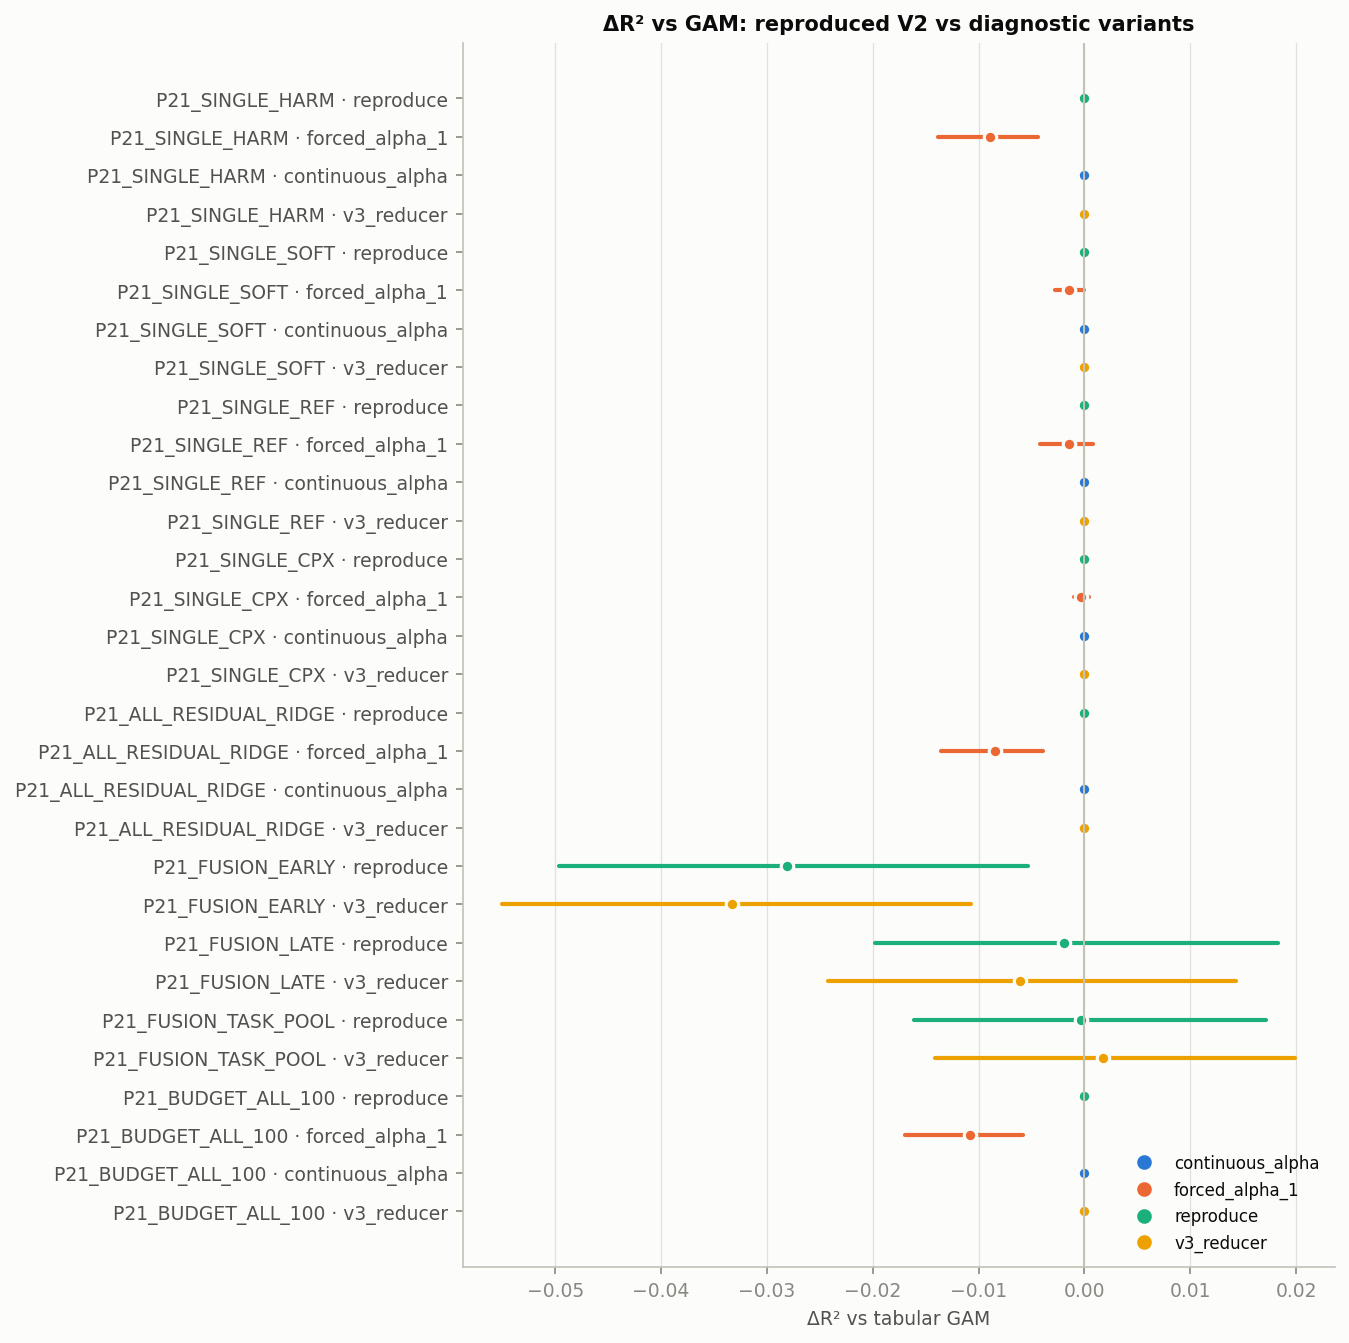

residual_alpha_by_fold.png


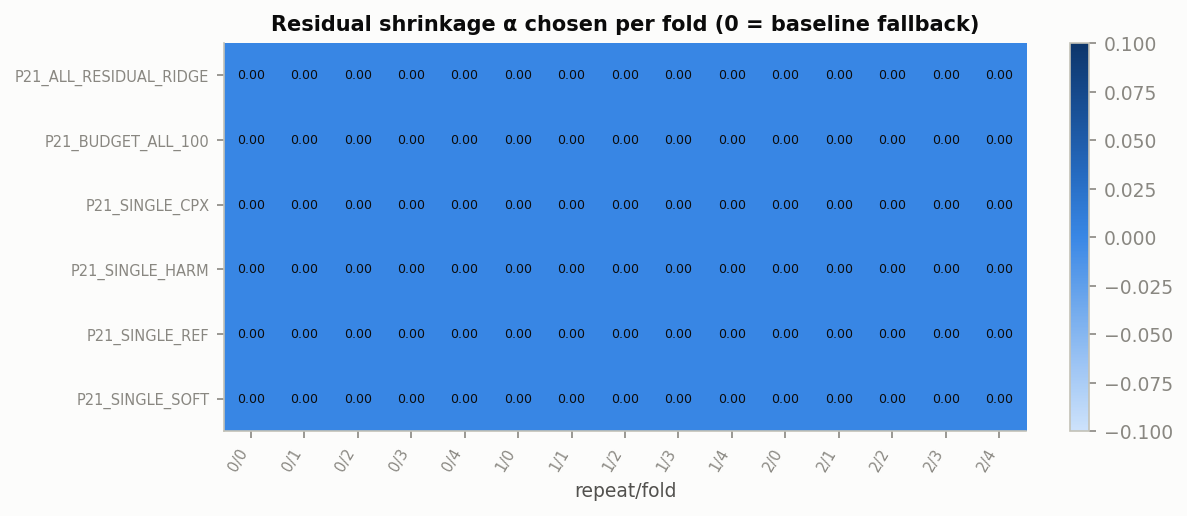

stage2_prediction_sd.png


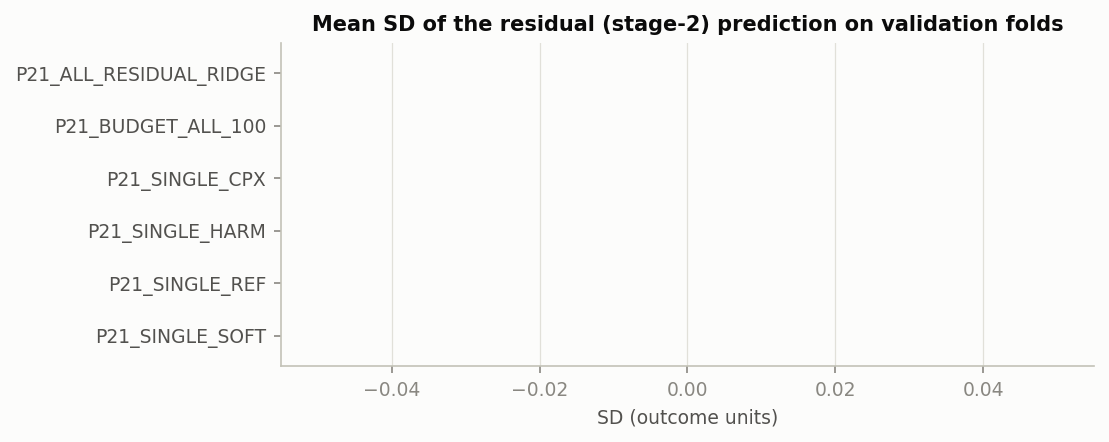

task_ensemble_extremes.png


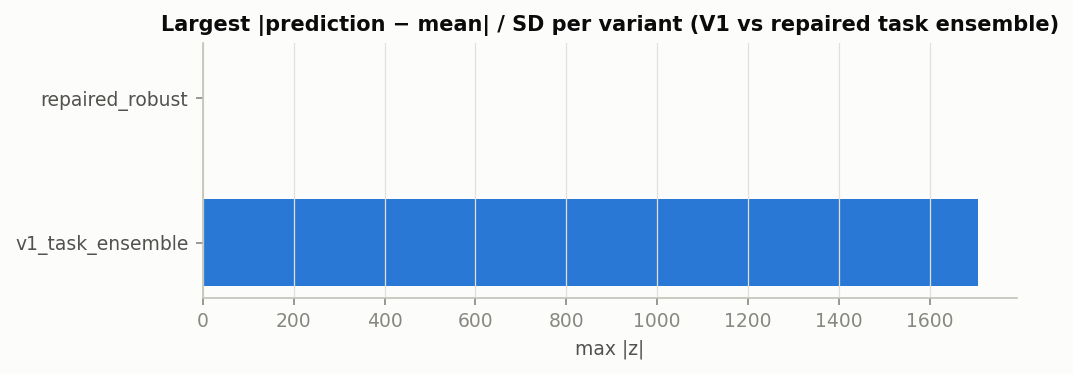

v2_budget_cap.png


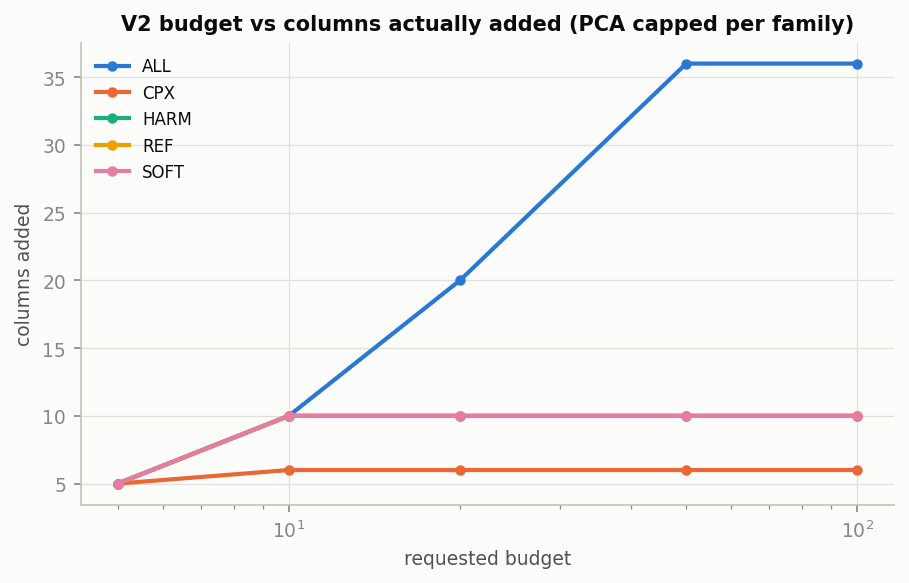

In [5]:
if RUN_PIPELINE and "P23" in FORCE_STAGES:
    display(nb.run_stages(ctx, ["P23"], ["P23"], enabled=True))
nb.p23_results(ctx)
nb.show_figures(ctx, "P23")

## 1. Environment and GPU diagnostics
Package versions, CUDA, VRAM, bf16, `.bin` loadability (transformers ≥ 4.50 refuses `torch.load` on torch < 2.6 → sha256-verified safetensors conversion instead of upgrading torch), hf_xet, qwen_asr/vLLM.

In [6]:
env = nb.environment()
display(env)
if not bool(env.loc["cuda_available", "value"]):
    print("WARNING: CUDA not available -> CPU only (slow); GPU-fit checks become WARN")
if not bool(env.loc["bin_weights_loadable", "value"]):
    print("NOTE:", env.loc["bin_weights_note", "value"])

c:\Users\myben\.conda\envs\MITSUI\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
python,3.10.18
platform,win32
torch_ok,True
torch_version,2.5.1+cu124
torchaudio_ok,True
torchaudio_version,2.5.1+cu124
transformers_ok,True
transformers_version,4.57.6
accelerate_ok,True
accelerate_version,1.15.0


NOTE: transformers 4.57.6 refuses torch.load of .bin weights with torch 2.5.1+cu124 < 2.6 (CVE-2025-32434); use the sha256-verified safetensors conversion (v3.asr.downloads.convert_verified_bin) instead of upgrading torch


## 2. Model eligibility and review decisions
Live, from local files only. Eligibility has 13 dimensions → one lifecycle status. Approvals exist **only** as named human reviews in
`configs/v3_asr_reviews.yaml`. `configs/v3_asr_review_proposals.yaml` holds drafts that approve nothing; drafts marked `ready: false`
carry open questions that only you can decide. Overlap approvals need a positive basis — "no known overlap" is refused.

In [7]:
rep = nb.eligibility_report(ctx, deep=DEEP_CHECK, verify_hashes=VERIFY_HASHES)
display(rep["summary"])
nb.show_eligibility_matrix(ctx, rep=rep)
display(rep["dimensions"].pivot(index="model_key", columns="dimension", values="status"))
for k in ("restrictions", "invalid_reviews", "policy", "license_policy"):
    if not rep[k].empty:
        print(f"--- {k}"); display(rep[k])

,model_key,priority,family,role,output,lifecycle,eligible,download_allowed,legal_status,provenance_status,checkpoint_status,framework_status,architecture,snapshot_origin,snapshot_kind,snapshot_revision,license,gpu_need_gb,manifest_gb
0,pasketti_phonetic,1,pasketti,child_phonetic,phones,LEGAL_REVIEW_PENDING,False,False,PENDING_REVIEW,PENDING_REVIEW,FAIL,NOT_PROBED,unknown,None,None,None,bigcode-openrail-m,NaN,1.262
1,whisper_small_en,2,whisper,general_word,words,LEGAL_REVIEW_PENDING,False,False,PENDING_REVIEW,PENDING_REVIEW,FAIL,NOT_PROBED,unknown,None,None,None,apache-2.0,NaN,0.971
2,pasketti_word,3,pasketti,child_word,words,LEGAL_REVIEW_PENDING,False,False,PENDING_REVIEW,PENDING_REVIEW,FAIL,NOT_PROBED,unknown,None,None,None,bigcode-openrail-m,NaN,4.092
3,wav2vec2_phoneme_espeak,4,wav2vec2,general_phonetic,phones,LEGAL_REVIEW_PENDING,False,False,PENDING_REVIEW,PENDING_REVIEW,FAIL,NOT_PROBED,unknown,None,None,None,apache-2.0,NaN,1.264
4,wav2vec2_base_960h,5,wav2vec2,general_char,chars,LEGAL_REVIEW_PENDING,False,False,PENDING_REVIEW,PENDING_REVIEW,PASS,NOT_PROBED,hf_ctc,hf_cache,hf_cache,22aad52d435eb6dbaf354bdad9b0da84ce7d6156,apache-2.0,1.34,0.378
5,wav2vec2_base,6,wav2vec2,frozen_encoder,embeddings,LEGAL_REVIEW_PENDING,False,False,PENDING_REVIEW,PENDING_REVIEW,FAIL,FAIL,hf_encoder,hf_cache,hf_cache,0b5b8e868dd84f03fd87d01f9c4ff0f080fecfe8,apache-2.0,1.34,0.380
6,hubert_base,7,hubert,frozen_encoder,embeddings,LEGAL_REVIEW_PENDING,False,False,PENDING_REVIEW,PENDING_REVIEW,FAIL,NOT_PROBED,unknown,None,None,None,apache-2.0,NaN,0.378
7,wavlm_base_plus,8,wavlm,frozen_encoder,embeddings,LEGAL_REVIEW_PENDING,False,False,PENDING_REVIEW,PENDING_REVIEW,FAIL,NOT_PROBED,unknown,None,None,None,cc-by-sa-3.0,NaN,0.378


<Figure size 965x560 with 1 Axes>

<Figure size 1100x480 with 1 Axes>

dimension,architecture_compatibility,checkpoint_availability,checkpoint_files,competition_permission,framework_dependencies,gpu_readiness,inference_readiness,license_approval,license_documentation,overlap_assessment,processor_compatibility,registry_validity,training_provenance
model_key,,,,,,,,,,,,,
hubert_base,NOT_PROBED,FAIL,NOT_PROBED,PASS,NOT_PROBED,NOT_PROBED,NOT_PROBED,PENDING,PASS,PENDING,NOT_PROBED,PASS,PENDING
pasketti_phonetic,NOT_PROBED,FAIL,NOT_PROBED,PASS,NOT_PROBED,NOT_PROBED,NOT_PROBED,PENDING,PASS,PENDING,NOT_PROBED,PASS,PENDING
pasketti_word,NOT_PROBED,FAIL,NOT_PROBED,PASS,NOT_PROBED,NOT_PROBED,NOT_PROBED,PENDING,PASS,PENDING,NOT_PROBED,PASS,PENDING
wav2vec2_base,PASS,PASS,FAIL,PASS,FAIL,PASS,NOT_PROBED,PENDING,PASS,PENDING,NOT_PROBED,PASS,PENDING
wav2vec2_base_960h,PASS,PASS,PASS,PASS,PASS,PASS,NOT_PROBED,PENDING,PASS,PENDING,NOT_PROBED,PASS,PENDING
wav2vec2_phoneme_espeak,NOT_PROBED,FAIL,NOT_PROBED,PASS,NOT_PROBED,NOT_PROBED,NOT_PROBED,PENDING,PASS,PENDING,NOT_PROBED,PASS,PENDING
wavlm_base_plus,NOT_PROBED,FAIL,NOT_PROBED,PENDING,NOT_PROBED,NOT_PROBED,NOT_PROBED,PENDING,PASS,PENDING,NOT_PROBED,PASS,PENDING
whisper_small_en,NOT_PROBED,FAIL,NOT_PROBED,PASS,NOT_PROBED,NOT_PROBED,NOT_PROBED,PENDING,PASS,PENDING,NOT_PROBED,PASS,PENDING


--- restrictions


,model_key,id,check,text,blocking
0,pasketti_phonetic,PSK-PH-LICENSE,license,"bigcode-openrail-m is a conditional license (use restrictions, not OSI). Approve only with every condition of licens...",True
1,pasketti_phonetic,PSK-PH-READNET-OVERLAP,overlap,"The card names ""ReadNet"" among the phonetic training corpora. This competition's audio comes from the Reach Every Re...",True
2,whisper_small_en,WSP-OVERLAP,overlap,"The web training set is not enumerated, so overlap cannot be ruled out by listing corpora. A positive basis is requi...",True
3,pasketti_word,PSK-WD-LICENSE,license,bigcode-openrail-m: conditional license; acknowledge every condition.,True
4,pasketti_word,PSK-WD-READNET-OVERLAP,overlap,"Same as PSK-PH-READNET-OVERLAP: ""ReadNet"" (Reach Every Reader data) is a named training corpus and one in-classroom ...",True
5,wavlm_base_plus,WLM-LICENSE,license,License of the weights is not stated on the model card (see license_policy.conditional.cc-by-sa-3.0). Approve only a...,True


--- policy


,competition,statement,recorded_by,source_url,rules_url,retrieved,permitted_families,named_families,general_rule_families,data_source,conditions
0,"Where the Wild Features Are (Literacy Speech Modeling), K-12 AI Infrastructure platform, hosted by DrivenData","""External data and pretrained models, including pretrained speech models such as wav2vec2, Whisper, and the Pasketti...","official competition pages, retrieved 2026-11-21",https://platform.k12-ai-infrastructure.org/competitions/4/literacy-speech-modeling/page/10/,https://platform.k12-ai-infrastructure.org/competitions/4/literacy-speech-modeling/rules/,2026-11-21,"whisper,wav2vec2,pasketti,hubert,wavlm","whisper,wav2vec2,pasketti","hubert,wavlm","Rules/about pages: ""The data come from the Reach Every Reader literacy screener, collected by MIT and Florida State ...",You may not upload competition data to any third-party services or APIs that retain the data (rules); all inference ...


--- license_policy


,license_id,class,conditions
0,apache-2.0,permissive,
1,mit,permissive,
2,bsd-2-clause,permissive,
3,bsd-3-clause,permissive,
4,cc0-1.0,permissive,
5,cc-by-4.0,permissive,
6,bigcode-openrail-m,openrail_use_restricted,OPENRAIL-USE-RESTRICTIONS: Attachment A use-based restrictions apply to the model and every derivative (e.g. no use ...
7,cc-by-sa-3.0,share_alike,CC-BY-SA-SHAREALIKE: Attribution + ShareAlike: adaptations of the licensed material must carry the same license. Com...
8,cc-by-nc-4.0,prohibited,
9,cc-by-nc-sa-4.0,prohibited,


In [8]:
rb = nb.review_board(ctx)
print("REVIEW STATE PER MODEL (decisions that are still yours)")
display(rb["models"])
cols = ["model_key", "check", "status", "reviewer", "date", "basis", "open_restrictions", "proposals_ready",
        "proposals_need_decision", "open_questions", "outstanding", "decision_needed"]
display(rb["checks"][[c for c in cols if c in rb["checks"]]])
print("\nEXACT COMMANDS (run in a terminal, never from this notebook):")
nb.review_commands(ctx)

REVIEW STATE PER MODEL (decisions that are still yours)


,model_key,priority,competition,license,overlap,provenance,rejected,reviews_complete,outstanding_decisions,ready_to_accept,needs_your_judgement
0,pasketti_phonetic,1,POLICY,PENDING,PENDING,PENDING,False,False,license: OpenRAIL-M is not OSI and carries use restrictions. Do you accept that the organisers' explicit naming of P...,P-PSKPH-P,"P-PSKPH-L,P-PSKPH-OV"
1,whisper_small_en,2,POLICY,PENDING,PENDING,PENDING,False,False,"license: no valid review recorded ; overlap: The web training set is not enumerated, so overlap cannot be ruled out ...","P-WSP-LP,P-WSP-OV,P-WSP-LP",
2,pasketti_word,3,POLICY,PENDING,PENDING,PENDING,False,False,"license: Same OpenRAIL-M question as P-PSKPH-L. | Runtime software (vLLM, qwen_asr) must itself be under an open sou...",,"P-PSKWD-L,P-PSKWD-OV,P-PSKWD-P"
3,wav2vec2_phoneme_espeak,4,POLICY,PENDING,PENDING,PENDING,False,False,license: no valid review recorded ; overlap: no valid review recorded ; provenance: no valid review recorded,"P-ESP-LP,P-ESP-OV,P-ESP-LP",
4,wav2vec2_base_960h,5,POLICY,PENDING,PENDING,PENDING,False,False,license: no valid review recorded ; overlap: no valid review recorded ; provenance: no valid review recorded,"P-B960-LP,P-B960-OV,P-B960-LP",
5,wav2vec2_base,6,POLICY,PENDING,PENDING,PENDING,False,False,license: no valid review recorded ; overlap: no valid review recorded ; provenance: no valid review recorded,"P-W2VB-LP,P-W2VB-OV,P-W2VB-LP",
6,hubert_base,7,POLICY,PENDING,PENDING,PENDING,False,False,license: no valid review recorded ; overlap: no valid review recorded ; provenance: no valid review recorded,"P-HUB-LP,P-HUB-OV,P-HUB-LP",
7,wavlm_base_plus,8,POLICY,PENDING,PENDING,PENDING,False,False,license: Which document governs the WEIGHTS: UniSpeech LICENSE (CC BY-SA 3.0) or unilm (MIT)? Neither says so explic...,P-WLM-OV,"P-WLM-LP,P-WLM-LP"


,model_key,check,status,reviewer,date,basis,open_restrictions,proposals_ready,proposals_need_decision,open_questions,outstanding,decision_needed
0,pasketti_phonetic,competition,POLICY,,,,,,,,,False
1,pasketti_phonetic,license,PENDING,,,,PSK-PH-LICENSE,,P-PSKPH-L,OpenRAIL-M is not OSI and carries use restrictions. Do you accept that the organisers' explicit naming of Pasketti s...,,True
2,pasketti_phonetic,overlap,PENDING,,,,PSK-PH-READNET-OVERLAP,,P-PSKPH-OV,"Overlap is LIKELY, not ruled out. Do you accept the model under the competition's explicit permission with the mitig...",,True
3,pasketti_phonetic,provenance,PENDING,,,,,P-PSKPH-P,,,,True
4,whisper_small_en,competition,POLICY,,,,,,,,,False
5,whisper_small_en,license,PENDING,,,,,P-WSP-LP,,,,True
6,whisper_small_en,overlap,PENDING,,,,WSP-OVERLAP,P-WSP-OV,,,,True
7,whisper_small_en,provenance,PENDING,,,,,P-WSP-LP,,,,True
8,pasketti_word,competition,POLICY,,,,,,,,,False
9,pasketti_word,license,PENDING,,,,PSK-WD-LICENSE,,P-PSKWD-L,"Same OpenRAIL-M question as P-PSKPH-L. | Runtime software (vLLM, qwen_asr) must itself be under an open source licen...",,True



EXACT COMMANDS (run in a terminal, never from this notebook):

## pasketti_phonetic · license — PENDING
   open questions: OpenRAIL-M is not OSI and carries use restrictions. Do you accept that the organisers' explicit naming of Pasketti satisfies the 'permissive open license' clause, or will you ask the forum first?
   [accept_after_deciding] python -m wildspeech.asr.reviews accept-proposal --id P-PSKPH-L --reviewer "<your full name>" --resolved-open-questions
   [record] python -m wildspeech.asr.reviews record --model pasketti_phonetic --checks license --decision approved --reviewer "<your full name>" --revision 675dfe392a2af7050f1374eeab4458cb1f003b3e --evidence-url <source url> --summary "<what you verified>" --license-id bigcode-openrail-m --resolves PSK-PH-LICENSE
   [reject] python -m wildspeech.asr.reviews record --model pasketti_phonetic --checks license --decision rejected --reviewer "<your full name>" --revision 675dfe392a2af7050f1374eeab4458cb1f003b3e --evidence-url https:

### Blocker-first preflight (no inference, no downloads)
This report separates technical checkpoint readiness from outstanding human model-use reviews. It does **not** approve any model. Downstream stages only run after accepted real ASR output exists.


In [9]:
# One concise action table instead of repeatedly running blocked P25-P29.
readiness = nb.stage_readiness(ctx)
board = nb.review_board(ctx)["models"]
print("MODEL REVIEW GATE — run review commands only after documenting evidence")
display(board[[c for c in ("model_key", "license", "overlap", "provenance", "reviews_complete", "outstanding_decisions") if c in board.columns]])
print("STAGE DEPENDENCIES")
display(readiness[[c for c in ("stage", "last_status", "inputs", "inputs_ready", "outcome") if c in readiness.columns]])
print("TECHNICAL DIAGNOSTIC (terminal, no model download):")
print("python asr_local_diagnostic.py --inspect")
print("For an authorized local audio smoke test after model-use review:")
print('python asr_local_diagnostic.py --audio "PATH_TO_AUTHORIZED_AUDIO.wav" --acknowledge-review')


MODEL REVIEW GATE — run review commands only after documenting evidence


,model_key,license,overlap,provenance,reviews_complete,outstanding_decisions
0,pasketti_phonetic,PENDING,PENDING,PENDING,False,license: OpenRAIL-M is not OSI and carries use restrictions. Do you accept that the organisers' explicit naming of P...
1,whisper_small_en,PENDING,PENDING,PENDING,False,"license: no valid review recorded ; overlap: The web training set is not enumerated, so overlap cannot be ruled out ..."
2,pasketti_word,PENDING,PENDING,PENDING,False,"license: Same OpenRAIL-M question as P-PSKPH-L. | Runtime software (vLLM, qwen_asr) must itself be under an open sou..."
3,wav2vec2_phoneme_espeak,PENDING,PENDING,PENDING,False,license: no valid review recorded ; overlap: no valid review recorded ; provenance: no valid review recorded
4,wav2vec2_base_960h,PENDING,PENDING,PENDING,False,license: no valid review recorded ; overlap: no valid review recorded ; provenance: no valid review recorded
5,wav2vec2_base,PENDING,PENDING,PENDING,False,license: no valid review recorded ; overlap: no valid review recorded ; provenance: no valid review recorded
6,hubert_base,PENDING,PENDING,PENDING,False,license: no valid review recorded ; overlap: no valid review recorded ; provenance: no valid review recorded
7,wavlm_base_plus,PENDING,PENDING,PENDING,False,license: Which document governs the WEIGHTS: UniSpeech LICENSE (CC BY-SA 3.0) or unilm (MIT)? Neither says so explic...


STAGE DEPENDENCIES


,stage,last_status,inputs,inputs_ready,outcome
0,P23,completed,V1/V2 artefacts,True,
1,P24,not_executed,eligible models (see model_readiness),None,ELIGIBILITY_ONLY
2,P25,not_executed,0/1 accepted ASR model(s): none,False,NOT_EXECUTED
3,P26,blocked,0/1 accepted ASR model(s): none,False,
4,P27,blocked,0/2 accepted ASR model(s): none,False,
5,P28,blocked,0/1 accepted ASR model(s): none,False,
6,P29,blocked,0/1 accepted ASR model(s): none,False,


TECHNICAL DIAGNOSTIC (terminal, no model download):
python asr_local_diagnostic.py --inspect
For an authorized local audio smoke test after model-use review:
python asr_local_diagnostic.py --audio "PATH_TO_AUTHORIZED_AUDIO.wav" --acknowledge-review


**Recording decisions (terminal, from `WildSpeech_GPU/`):**
```powershell
python -m wildspeech.asr.reviews board                      # what is open
python -m wildspeech.asr.reviews commands                   # every open decision with accept / reject / defer lines

# drafts that are ready (you read the cited sources at the pinned revision):
python -m wildspeech.asr.reviews accept-proposal --id P-B960-LP P-B960-OV --reviewer "<your full name>"
python -m wildspeech.asr.reviews accept-proposal --id P-WSP-LP P-WSP-OV --reviewer "<your full name>"
python -m wildspeech.asr.reviews accept-proposal --id P-ESP-LP P-ESP-OV P-W2VB-LP P-W2VB-OV P-HUB-LP P-HUB-OV --reviewer "<your full name>"

# Pasketti (ReadNet overlap) — choose ONE per model:
python -m wildspeech.asr.reviews accept-proposal --id P-PSKPH-L P-PSKPH-P P-PSKPH-OV --reviewer "<your full name>" --resolved-open-questions --mitigation "<your own mitigation>"
python -m wildspeech.asr.reviews record --model pasketti_phonetic --checks overlap --decision rejected --reviewer "<your full name>" --revision 675dfe392a2af7050f1374eeab4458cb1f003b3e --evidence-url https://huggingface.co/drivendata/pasketti-phonetic --summary "ReadNet in training data; overlap with these children not acceptable"
python -m wildspeech.asr.reviews defer --model pasketti_phonetic --checks overlap --reviewer "<your full name>" --revision 675dfe392a2af7050f1374eeab4458cb1f003b3e --outstanding "Awaiting an organiser ruling on ReadNet overlap"

python -m wildspeech.asr.reviews show                       # every entry and whether it validates
```
wavlm_base_plus: its weights' license is unclear (CC BY-SA 3.0 via UniSpeech vs MIT code) — `P-WLM-LP` is `ready: false`; accept only after deciding which document governs the weights, otherwise reject or defer (the model is optional).

## 3. Checkpoint status and downloads
A complete Hugging Face cache snapshot at the pinned commit is used in place. A partial one is completed **in the cache**: first from
LFS blobs already on disk (content-addressed by sha256, so no revision is ever mixed), then by fetching only the missing files at the
pinned commit. Small git files (configs, `preprocessor_config.json`) are never borrowed from another revision. Only APPROVED models
are installed, and only when `ALLOW_MODEL_DOWNLOADS = True`.

In [10]:
display(nb.installed_checkpoints(ctx))
inv = nb.revision_inventory(ctx)
if not inv.empty:
    print("--- which cached revision holds which manifest file (pinned = the only one used)")
    display(inv.pivot_table(index=["model_key", "file"], columns="snapshot", values="present", aggfunc="first"))
rp = nb.repair_plan(ctx)
print("--- pinned snapshot: present / repairable offline / must be fetched at the pinned commit")
display(rp[~rp["pinned_present"]] if not rp.empty else rp)
plan = nb.install_plan(ctx)
display(plan)
print(f"to download: {plan['download_gb'].sum():.2f} GB | conversions: {int(plan['conversion_needed'].sum())}")

,model_key,installed,origin,kind,path,revision,revision_source,pinned,architecture,manifest_gb,problems,searched
0,pasketti_phonetic,False,None,None,None,None,None,675dfe392a2af7050f1374eeab4458cb1f003b3e,None,1.262,checkpoint not on disk at pinned revision 675dfe392a2af7050f1374eeab4458cb1f003b3e (searched: C:\Users\myben\Downloa...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\pasketti_phonetic; C:\Users\myben\.cache\huggingface\hub
1,whisper_small_en,False,None,None,None,None,None,e8727524f962ee844a7319d92be39ac1bd25655a,None,0.971,checkpoint not on disk at pinned revision e8727524f962ee844a7319d92be39ac1bd25655a (searched: C:\Users\myben\Downloa...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\whisper_small_en; C:\Users\myben\.cache\huggingface\hub
2,pasketti_word,False,None,None,None,None,None,7756647568342982e5f9777f1c34fdcd5fa59866,None,4.092,checkpoint not on disk at pinned revision 7756647568342982e5f9777f1c34fdcd5fa59866 (searched: C:\Users\myben\Downloa...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\pasketti_word; C:\Users\myben\.cache\huggingface\hub
3,wav2vec2_phoneme_espeak,False,None,None,None,None,None,ae45363bf3413b374fecd9dc8bc1df0e24c3b7f4,None,1.264,checkpoint not on disk at pinned revision ae45363bf3413b374fecd9dc8bc1df0e24c3b7f4 (searched: C:\Users\myben\Downloa...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wav2vec2_phoneme; C:\Users\myben\.cache\huggingface\hub
4,wav2vec2_base_960h,True,hf_cache,hf_cache,C:\Users\myben\.cache\huggingface\hub\models--facebook--wav2vec2-base-960h\snapshots\22aad52d435eb6dbaf354bdad9b0da8...,22aad52d435eb6dbaf354bdad9b0da84ce7d6156,hf_cache_path,22aad52d435eb6dbaf354bdad9b0da84ce7d6156,hf_ctc,0.378,,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wav2vec2_base_960h; C:\Users\myben\.cache\huggingface\hub
5,wav2vec2_base,False,hf_cache,hf_cache,C:\Users\myben\.cache\huggingface\hub\models--facebook--wav2vec2-base\snapshots\0b5b8e868dd84f03fd87d01f9c4ff0f080fe...,0b5b8e868dd84f03fd87d01f9c4ff0f080fecfe8,hf_cache_path,0b5b8e868dd84f03fd87d01f9c4ff0f080fecfe8,hf_encoder,0.380,missing preprocessor_config.json,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wav2vec2_base; C:\Users\myben\.cache\huggingface\hub
6,hubert_base,False,None,None,None,None,None,dba3bb02fda4248b6e082697eee756de8fe8aa8a,None,0.378,checkpoint not on disk at pinned revision dba3bb02fda4248b6e082697eee756de8fe8aa8a (searched: C:\Users\myben\Downloa...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\hubert_base; C:\Users\myben\.cache\huggingface\hub
7,wavlm_base_plus,False,None,None,None,None,None,4c66d4806a428f2e922ccfa1a962776e232d487b,None,0.378,checkpoint not on disk at pinned revision 4c66d4806a428f2e922ccfa1a962776e232d487b (searched: C:\Users\myben\Downloa...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wavlm_base_plus; C:\Users\myben\.cache\huggingface\hub


--- which cached revision holds which manifest file (pinned = the only one used)


snapshot                                    0b5b8e868dd84f03fd87d01f9c4ff0f080fecfe8 22aad52d435eb6dbaf354bdad9b0da84ce7d6156 f30924bbbfbf6058e04aab549531ea55c74928d0
model_key          file                                                                                                                                               
wav2vec2_base      config.json                                                  True                                      NaN                                    False
                   preprocessor_config.json                                    False                                      NaN                                    False
                   pytorch_model.bin                                            True                                      NaN                                    False
wav2vec2_base_960h config.json                                                   NaN                                     True                                      NaN
                   model.safetensors                                             NaN                                     True                                      NaN
                   preprocessor_config.json                                      NaN                                     True                                      NaN
                   special_tokens_map.json                                       NaN                                     True                                      NaN
                   tokenizer_config.json                                         NaN                                     True                                      NaN
                   vocab.json                                                    NaN                                     True                                      NaN

--- pinned snapshot: present / repairable offline / must be fetched at the pinned commit


,model_key,file,size,pinned_present,lfs_sha256,offline_repairable,needs_download,note
0,pasketti_phonetic,config.json,2396,False,False,False,True,small git file: fetch at the pinned commit (never borrowed from another revision)
1,pasketti_phonetic,preprocessor_config.json,256,False,False,False,True,small git file: fetch at the pinned commit (never borrowed from another revision)
2,pasketti_phonetic,vocab.json,634,False,False,False,True,small git file: fetch at the pinned commit (never borrowed from another revision)
3,pasketti_phonetic,tokenizer_config.json,794,False,False,False,True,small git file: fetch at the pinned commit (never borrowed from another revision)
4,pasketti_phonetic,special_tokens_map.json,53,False,False,False,True,small git file: fetch at the pinned commit (never borrowed from another revision)
5,pasketti_phonetic,added_tokens.json,18,False,False,False,True,small git file: fetch at the pinned commit (never borrowed from another revision)
6,pasketti_phonetic,model.safetensors,1262097724,False,True,False,True,not cached: fetch at the pinned commit
7,whisper_small_en,config.json,1943,False,False,False,True,small git file: fetch at the pinned commit (never borrowed from another revision)
8,whisper_small_en,generation_config.json,1931,False,False,False,True,small git file: fetch at the pinned commit (never borrowed from another revision)
9,whisper_small_en,preprocessor_config.json,184990,False,False,False,True,small git file: fetch at the pinned commit (never borrowed from another revision)


,model_key,hf_id,revision,storage,path,local_dir,lifecycle,download_allowed,manifest_files,present_files,missing_files,download_bytes,download_gb,conversion_needed,conversion_note,conversion_gb,disk_free_gb,disk_ok
0,pasketti_phonetic,drivendata/pasketti-phonetic,675dfe392a2af7050f1374eeab4458cb1f003b3e,local_dir,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\pasketti_phonetic,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\pasketti_phonetic,LEGAL_REVIEW_PENDING,False,7,0,"config.json,preprocessor_config.json,vocab.json,tokenizer_config.json,special_tokens_map.json,added_tokens.json,mode...",1262101875,1.262,False,,0.000,367.45,True
1,whisper_small_en,openai/whisper-small.en,e8727524f962ee844a7319d92be39ac1bd25655a,local_dir,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\whisper_small_en,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\whisper_small_en,LEGAL_REVIEW_PENDING,False,11,0,"config.json,generation_config.json,preprocessor_config.json,tokenizer.json,tokenizer_config.json,vocab.json,merges.t...",970930930,0.971,False,,0.000,367.45,True
2,pasketti_word,drivendata/pasketti-word,7756647568342982e5f9777f1c34fdcd5fa59866,local_dir,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\pasketti_word,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\pasketti_word,LEGAL_REVIEW_PENDING,False,11,0,"config.json,generation_config.json,preprocessor_config.json,chat_template.json,tokenizer.json,tokenizer_config.json,...",4092092591,4.092,False,,0.000,367.45,True
3,wav2vec2_phoneme_espeak,facebook/wav2vec2-lv-60-espeak-cv-ft,ae45363bf3413b374fecd9dc8bc1df0e24c3b7f4,local_dir,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wav2vec2_phoneme,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wav2vec2_phoneme,LEGAL_REVIEW_PENDING,False,6,0,"config.json,preprocessor_config.json,vocab.json,tokenizer_config.json,special_tokens_map.json,pytorch_model.bin",1263542238,1.264,True,transformers 4.57.6 refuses torch.load of .bin weights with torch 2.5.1+cu124 < 2.6 (CVE-2025-32434); use the sha256...,1.264,367.45,True
4,wav2vec2_base_960h,facebook/wav2vec2-base-960h,22aad52d435eb6dbaf354bdad9b0da84ce7d6156,hf_cache_in_place,C:\Users\myben\.cache\huggingface\hub\models--facebook--wav2vec2-base-960h\snapshots\22aad52d435eb6dbaf354bdad9b0da8...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wav2vec2_base_960h,LEGAL_REVIEW_PENDING,False,6,6,,0,0.000,False,,0.000,367.45,True
5,wav2vec2_base,facebook/wav2vec2-base,0b5b8e868dd84f03fd87d01f9c4ff0f080fecfe8,hf_cache,C:\Users\myben\.cache\huggingface\hub\models--facebook--wav2vec2-base\snapshots\0b5b8e868dd84f03fd87d01f9c4ff0f080fe...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wav2vec2_base,LEGAL_REVIEW_PENDING,False,3,2,preprocessor_config.json,159,0.000,True,transformers 4.57.6 refuses torch.load of .bin weights with torch 2.5.1+cu124 < 2.6 (CVE-2025-32434); use the sha256...,0.380,367.45,True
6,hubert_base,facebook/hubert-base-ls960,dba3bb02fda4248b6e082697eee756de8fe8aa8a,local_dir,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\hubert_base,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\hubert_base,LEGAL_REVIEW_PENDING,False,3,0,"config.json,preprocessor_config.json,pytorch_model.bin",377571352,0.378,True,transformers 4.57.6 refuses torch.load of .bin weights with torch 2.5.1+cu124 < 2.6 (CVE-2025-32434); use the sha256...,0.378,367.45,True
7,wavlm_base_plus,microsoft/wavlm-base-plus,4c66d4806a428f2e922ccfa1a962776e232d487b,local_dir,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wavlm_base_plus,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wavlm_base_plus,LEGAL_REVIEW_PENDING,False,3,0,"config.json,preprocessor_config.json,pytorch_model.bin",377619872,0.378,True,transformers 4.57.6 refuses torch.load of .bin weights with torch 2.5.1+cu124 < 2.6 (CVE-2025-32434); use the sha256...,0.378,367.45,True


to download: 8.35 GB | conversions: 4


In [11]:
# Download is a separate, explicit action; never use it as a way to bypass review.
if ALLOW_MODEL_DOWNLOADS:
    print("Download requested: the source manager will still enforce every evidence-backed review.")
    res = nb.install(ctx, allow=True, verify=True)
    display(res if not res.empty else "NO_RESULTS: no eligible models downloaded")
else:
    print("Downloads disabled (ALLOW_MODEL_DOWNLOADS=False). Showing local inventory only.")
    display(nb.installed_checkpoints(ctx))
print("Manual install commands / review blockers:")
display(rep.get("downloads", pd.DataFrame()))


Downloads disabled (ALLOW_MODEL_DOWNLOADS=False). Showing local inventory only.


,model_key,installed,origin,kind,path,revision,revision_source,pinned,architecture,manifest_gb,problems,searched
0,pasketti_phonetic,False,None,None,None,None,None,675dfe392a2af7050f1374eeab4458cb1f003b3e,None,1.262,checkpoint not on disk at pinned revision 675dfe392a2af7050f1374eeab4458cb1f003b3e (searched: C:\Users\myben\Downloa...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\pasketti_phonetic; C:\Users\myben\.cache\huggingface\hub
1,whisper_small_en,False,None,None,None,None,None,e8727524f962ee844a7319d92be39ac1bd25655a,None,0.971,checkpoint not on disk at pinned revision e8727524f962ee844a7319d92be39ac1bd25655a (searched: C:\Users\myben\Downloa...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\whisper_small_en; C:\Users\myben\.cache\huggingface\hub
2,pasketti_word,False,None,None,None,None,None,7756647568342982e5f9777f1c34fdcd5fa59866,None,4.092,checkpoint not on disk at pinned revision 7756647568342982e5f9777f1c34fdcd5fa59866 (searched: C:\Users\myben\Downloa...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\pasketti_word; C:\Users\myben\.cache\huggingface\hub
3,wav2vec2_phoneme_espeak,False,None,None,None,None,None,ae45363bf3413b374fecd9dc8bc1df0e24c3b7f4,None,1.264,checkpoint not on disk at pinned revision ae45363bf3413b374fecd9dc8bc1df0e24c3b7f4 (searched: C:\Users\myben\Downloa...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wav2vec2_phoneme; C:\Users\myben\.cache\huggingface\hub
4,wav2vec2_base_960h,True,hf_cache,hf_cache,C:\Users\myben\.cache\huggingface\hub\models--facebook--wav2vec2-base-960h\snapshots\22aad52d435eb6dbaf354bdad9b0da8...,22aad52d435eb6dbaf354bdad9b0da84ce7d6156,hf_cache_path,22aad52d435eb6dbaf354bdad9b0da84ce7d6156,hf_ctc,0.378,,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wav2vec2_base_960h; C:\Users\myben\.cache\huggingface\hub
5,wav2vec2_base,False,hf_cache,hf_cache,C:\Users\myben\.cache\huggingface\hub\models--facebook--wav2vec2-base\snapshots\0b5b8e868dd84f03fd87d01f9c4ff0f080fe...,0b5b8e868dd84f03fd87d01f9c4ff0f080fecfe8,hf_cache_path,0b5b8e868dd84f03fd87d01f9c4ff0f080fecfe8,hf_encoder,0.380,missing preprocessor_config.json,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wav2vec2_base; C:\Users\myben\.cache\huggingface\hub
6,hubert_base,False,None,None,None,None,None,dba3bb02fda4248b6e082697eee756de8fe8aa8a,None,0.378,checkpoint not on disk at pinned revision dba3bb02fda4248b6e082697eee756de8fe8aa8a (searched: C:\Users\myben\Downloa...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\hubert_base; C:\Users\myben\.cache\huggingface\hub
7,wavlm_base_plus,False,None,None,None,None,None,4c66d4806a428f2e922ccfa1a962776e232d487b,None,0.378,checkpoint not on disk at pinned revision 4c66d4806a428f2e922ccfa1a962776e232d487b (searched: C:\Users\myben\Downloa...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wavlm_base_plus; C:\Users\myben\.cache\huggingface\hub


Manual install commands / review blockers:


,model_key,hf_id,hf_id_status,revision,target_dir,download_gb,project_cli,project_script,powershell_script,huggingface_cli,note,lifecycle,download_allowed
0,pasketti_phonetic,drivendata/pasketti-phonetic,verified_public,675dfe392a2af7050f1374eeab4458cb1f003b3e,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\pasketti_phonetic,1.262,python -m wildspeech v3-install --model pasketti_phonetic --execute,python scripts\v3_download_asr_models.py --model pasketti_phonetic --execute,.\scripts\v3_download_asr_models.ps1 -Model pasketti_phonetic -Execute,"huggingface-cli download drivendata/pasketti-phonetic ""config.json"" ""preprocessor_config.json"" ""vocab.json"" ""tokeniz...",downloads only after the model's reviews pass; review the card at the pinned revision,LEGAL_REVIEW_PENDING,False
1,whisper_small_en,openai/whisper-small.en,verified_public,e8727524f962ee844a7319d92be39ac1bd25655a,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\whisper_small_en,0.971,python -m wildspeech v3-install --model whisper_small_en --execute,python scripts\v3_download_asr_models.py --model whisper_small_en --execute,.\scripts\v3_download_asr_models.ps1 -Model whisper_small_en -Execute,"huggingface-cli download openai/whisper-small.en ""config.json"" ""generation_config.json"" ""preprocessor_config.json"" ""...",downloads only after the model's reviews pass; review the card at the pinned revision,LEGAL_REVIEW_PENDING,False
2,pasketti_word,drivendata/pasketti-word,verified_public,7756647568342982e5f9777f1c34fdcd5fa59866,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\pasketti_word,4.092,python -m wildspeech v3-install --model pasketti_word --execute,python scripts\v3_download_asr_models.py --model pasketti_word --execute,.\scripts\v3_download_asr_models.ps1 -Model pasketti_word -Execute,"huggingface-cli download drivendata/pasketti-word ""config.json"" ""generation_config.json"" ""preprocessor_config.json"" ...",downloads only after the model's reviews pass; review the card at the pinned revision,LEGAL_REVIEW_PENDING,False
3,wav2vec2_phoneme_espeak,facebook/wav2vec2-lv-60-espeak-cv-ft,verified_public,ae45363bf3413b374fecd9dc8bc1df0e24c3b7f4,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wav2vec2_phoneme,1.264,python -m wildspeech v3-install --model wav2vec2_phoneme_espeak --execute,python scripts\v3_download_asr_models.py --model wav2vec2_phoneme_espeak --execute,.\scripts\v3_download_asr_models.ps1 -Model wav2vec2_phoneme_espeak -Execute,"huggingface-cli download facebook/wav2vec2-lv-60-espeak-cv-ft ""config.json"" ""preprocessor_config.json"" ""vocab.json"" ...",downloads only after the model's reviews pass; review the card at the pinned revision,LEGAL_REVIEW_PENDING,False
4,hubert_base,facebook/hubert-base-ls960,verified_public,dba3bb02fda4248b6e082697eee756de8fe8aa8a,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\hubert_base,0.378,python -m wildspeech v3-install --model hubert_base --execute,python scripts\v3_download_asr_models.py --model hubert_base --execute,.\scripts\v3_download_asr_models.ps1 -Model hubert_base -Execute,"huggingface-cli download facebook/hubert-base-ls960 ""config.json"" ""preprocessor_config.json"" ""pytorch_model.bin"" --r...",downloads only after the model's reviews pass; review the card at the pinned revision,LEGAL_REVIEW_PENDING,False
5,wavlm_base_plus,microsoft/wavlm-base-plus,verified_public,4c66d4806a428f2e922ccfa1a962776e232d487b,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wavlm_base_plus,0.378,python -m wildspeech v3-install --model wavlm_base_plus --execute,python scripts\v3_download_asr_models.py --model wavlm_base_plus --execute,.\scripts\v3_download_asr_models.ps1 -Model wavlm_base_plus -Execute,"huggingface-cli download microsoft/wavlm-base-plus ""config.json"" ""preprocessor_config.json"" ""pytorch_model.bin"" --re...",downloads only after the model's reviews pass; review the card at the pinned revision,LEGAL_REVIEW_PENDING,Fal

## 4. Model-loading diagnostics and smoke inference
1. processor / tokenizer contract (no weights); 2. **technical load check** — weights + forward pass on synthetic audio for every model
whose checkpoint and framework dimensions pass (no review needed, no competition data); 3. few-clip **smoke decode** of training clips
for fully eligible models (non-empty, finite output required). One GPU model at a time.

In [12]:
cc = nb.component_checks(ctx)
display(cc if not cc.empty else "NO_RESULTS: no complete local models")
if RUN_SMOKE:
    print("Explicit local smoke requested; review gate remains enforced.")
    lc = nb.load_checks(ctx)
    display(lc if not lc.empty else "NO_RESULTS: no loadable models")
    sm = nb.smoke(ctx, clips=8)
    display(sm if not sm.empty else "NO_RESULTS: no eligible models for smoke inference")
else:
    print("RUN_SMOKE=False: no model loading or inference")
display(nb.model_readiness(ctx))


c:\Users\myben\.conda\envs\MITSUI\lib\site-packages\transformers\configuration_utils.py:335: UserWarning: Passing `gradient_checkpointing` to a config initialization is deprecated and will be removed in v5 Transformers. Using `model.gradient_checkpointing_enable()` instead, or if you are using the `Trainer` API, pass `gradient_checkpointing=True` in your `TrainingArguments`.
  warnings.warn(


,model_key,architecture,path,ok,problems,notes,model_type,architectures,sampling_rate,vocab_size,tokenizer_class,feat_extract_norm,return_attention_mask,pad_token,word_delimiter,letters
0,wav2vec2_base_960h,hf_ctc,C:\Users\myben\.cache\huggingface\hub\models--facebook--wav2vec2-base-960h\snapshots\22aad52d435eb6dbaf354bdad9b0da8...,True,,,wav2vec2,Wav2Vec2ForCTC,16000.0,32.0,Wav2Vec2CTCTokenizer,group,False,<pad>,|,26.0
1,wav2vec2_base,hf_encoder,C:\Users\myben\.cache\huggingface\hub\models--facebook--wav2vec2-base\snapshots\0b5b8e868dd84f03fd87d01f9c4ff0f080fe...,False,OSError: Can't load feature extractor for 'C:\Users\myben\.cache\huggingface\hub\models--facebook--wav2vec2-base\sna...,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


RUN_SMOKE=False: no model loading or inference


,model_key,priority,role,output,lifecycle,reviews,outstanding_decisions,download_auth,download_flag,installed,checkpoint_detail,technical,technical_error,smoke,inference,accepted_output,eligible_for_inference,next_action
0,pasketti_phonetic,1,child_phonetic,phones,LEGAL_REVIEW_PENDING,PENDING,license: OpenRAIL-M is not OSI and carries use restrictions. Do you accept that the organisers' explicit naming of P...,False,ALLOW_MODEL_DOWNLOADS is not enabled,False,no snapshot,NOT_CHECKED,,NOT_PROBED,never_run,False,False,review decision: python -m wildspeech.asr.reviews commands --model pasketti_phonetic
1,whisper_small_en,2,general_word,words,LEGAL_REVIEW_PENDING,PENDING,"license: no valid review recorded ; overlap: The web training set is not enumerated, so overlap cannot be ruled out ...",False,ALLOW_MODEL_DOWNLOADS is not enabled,False,no snapshot,NOT_CHECKED,,NOT_PROBED,never_run,False,False,review decision: python -m wildspeech.asr.reviews commands --model whisper_small_en
2,pasketti_word,3,child_word,words,LEGAL_REVIEW_PENDING,PENDING,"license: Same OpenRAIL-M question as P-PSKPH-L. | Runtime software (vLLM, qwen_asr) must itself be under an open sou...",False,ALLOW_MODEL_DOWNLOADS is not enabled,False,no snapshot,NOT_CHECKED,,NOT_PROBED,never_run,False,False,review decision: python -m wildspeech.asr.reviews commands --model pasketti_word
3,wav2vec2_phoneme_espeak,4,general_phonetic,phones,LEGAL_REVIEW_PENDING,PENDING,license: no valid review recorded ; overlap: no valid review recorded ; provenance: no valid review recorded,False,ALLOW_MODEL_DOWNLOADS is not enabled,False,no snapshot,NOT_CHECKED,,NOT_PROBED,never_run,False,False,review decision: python -m wildspeech.asr.reviews commands --model wav2vec2_phoneme_espeak
4,wav2vec2_base_960h,5,general_char,chars,LEGAL_REVIEW_PENDING,PENDING,license: no valid review recorded ; overlap: no valid review recorded ; provenance: no valid review recorded,False,ALLOW_MODEL_DOWNLOADS is not enabled,True,6/6 manifest files present at the published size,LOAD_OK,,NOT_PROBED,never_run,False,False,review decision: python -m wildspeech.asr.reviews commands --model wav2vec2_base_960h
5,wav2vec2_base,6,frozen_encoder,embeddings,LEGAL_REVIEW_PENDING,PENDING,license: no valid review recorded ; overlap: no valid review recorded ; provenance: no valid review recorded,False,ALLOW_MODEL_DOWNLOADS is not enabled,False,missing preprocessor_config.json,NOT_CHECKED,,NOT_PROBED,never_run,False,False,review decision: python -m wildspeech.asr.reviews commands --model wav2vec2_base
6,hubert_base,7,frozen_encoder,embeddings,LEGAL_REVIEW_PENDING,PENDING,license: no valid review recorded ; overlap: no valid review recorded ; provenance: no valid review recorded,False,ALLOW_MODEL_DOWNLOADS is not enabled,False,no snapshot,NOT_CHECKED,,NOT_PROBED,never_run,False,False,review decision: python -m wildspeech.asr.reviews commands --model hubert_base
7,wavlm_base_plus,8,frozen_encoder,embeddings,LEGAL_REVIEW_PENDING,PENDING,license: Which document governs the WEIGHTS: UniSpeech LICENSE (CC BY-SA 3.0) or unilm (MIT)? Neither says so explic...,False,ALLOW_MODEL_DOWNLOADS is not enabled,False,no snapshot,NOT_CHECKED,,NOT_PROBED,never_run,False,False,review decision: python -m wildspeech.asr.reviews commands --model wavlm_base_plus


## 5. Full ASR extraction (P24)
Eligibility → gated install → smoke → resumable inference (priority order, one GPU model at a time, duration-aware batches, OOM halving,
fp16/bf16 guard with fp32 fallback, single-clip CPU fallback, streaming TAR reads, Parquet checkpoints). The live tqdm bar shows %, ETA,
clips/s, RAM, VRAM and failures. Interrupting is safe: finished clips are flushed and resume skips them.
`ELIGIBILITY_ONLY` means **no inference ran** (stage status `not_executed`).

In [13]:
if RUN_PIPELINE:
    # P24 can report ELIGIBILITY_ONLY; do not claim inference ran.
    display(nb.run_stages(ctx, ["P24"], FORCE_ARG, enabled=True))
else:
    print("P24 PLANNED: set RUN_PIPELINE=True only after resolving the model review gates")
out = nb.p24_outcome(ctx) or {}
print("P24 stage outcome:", out.get("stage_outcome", "NOT_EXECUTED"))
print("Actual inference executed:", bool(out.get("inference_executed", False)))
print("Accepted real inference outputs:", accepted_asr_models())


P24 PLANNED: set RUN_PIPELINE=True only after resolving the model review gates
P24 stage outcome: ELIGIBILITY_ONLY
Actual inference executed: False
Accepted real inference outputs: []


,model_key,split,state,rows,failures,candidates,coverage,origin,accepted
0,pasketti_phonetic,train,never_run,0,0,14704,0.0,none,False
1,whisper_small_en,train,never_run,0,0,14704,0.0,none,False
2,pasketti_word,train,never_run,0,0,14704,0.0,none,False
3,wav2vec2_phoneme_espeak,train,never_run,0,0,14704,0.0,none,False
4,wav2vec2_base_960h,train,never_run,0,0,14704,0.0,none,False
5,wav2vec2_base,train,never_run,0,0,14704,0.0,none,False
6,hubert_base,train,never_run,0,0,14704,0.0,none,False
7,wavlm_base_plus,train,never_run,0,0,14704,0.0,none,False


<Figure size 700x340 with 1 Axes>

[P24/not_executed]


,stage,status,reason,n_models,inference_executed,eligible,not_eligible,lifecycle,cuda_available,gpu,installed,stage_outcome,accepted_models
0,P24,NOT_EXECUTED,eligibility only: no speech model is READY_FOR_INFERENCE (see model_eligibility.csv / required_actions.csv); no infe...,8,False,[],"['pasketti_phonetic', 'whisper_small_en', 'pasketti_word', 'wav2vec2_phoneme_espeak', 'wav2vec2_base_960h', 'wav2vec...","{'pasketti_phonetic': 'LEGAL_REVIEW_PENDING', 'whisper_small_en': 'LEGAL_REVIEW_PENDING', 'pasketti_word': 'LEGAL_RE...",True,NVIDIA GeForce RTX 3070 Laptop GPU,[],ELIGIBILITY_ONLY,[]


[P24/model_readiness]


,model_key,priority,role,output,lifecycle,reviews,outstanding_decisions,download_auth,download_flag,installed,checkpoint_detail,technical,technical_error,smoke,inference,accepted_output,eligible_for_inference,next_action
0,pasketti_phonetic,1,child_phonetic,phones,LEGAL_REVIEW_PENDING,PENDING,license: OpenRAIL-M is not OSI and carries use restrictions. Do you accept that the organisers' explicit naming of P...,False,v3.asr.downloads.allow_model_downloads,False,no snapshot,NOT_CHECKED,NaN,NOT_PROBED,never_run,False,False,review decision: python -m wildspeech.asr.reviews commands --model pasketti_phonetic
1,whisper_small_en,2,general_word,words,LEGAL_REVIEW_PENDING,PENDING,"license: no valid review recorded ; overlap: The web training set is not enumerated, so overlap cannot be ruled out ...",False,v3.asr.downloads.allow_model_downloads,False,no snapshot,NOT_CHECKED,NaN,NOT_PROBED,never_run,False,False,review decision: python -m wildspeech.asr.reviews commands --model whisper_small_en
2,pasketti_word,3,child_word,words,LEGAL_REVIEW_PENDING,PENDING,"license: Same OpenRAIL-M question as P-PSKPH-L. | Runtime software (vLLM, qwen_asr) must itself be under an open sou...",False,v3.asr.downloads.allow_model_downloads,False,no snapshot,NOT_CHECKED,NaN,NOT_PROBED,never_run,False,False,review decision: python -m wildspeech.asr.reviews commands --model pasketti_word
3,wav2vec2_phoneme_espeak,4,general_phonetic,phones,LEGAL_REVIEW_PENDING,PENDING,license: no valid review recorded ; overlap: no valid review recorded ; provenance: no valid review recorded,False,v3.asr.downloads.allow_model_downloads,False,no snapshot,NOT_CHECKED,NaN,NOT_PROBED,never_run,False,False,review decision: python -m wildspeech.asr.reviews commands --model wav2vec2_phoneme_espeak
4,wav2vec2_base_960h,5,general_char,chars,LEGAL_REVIEW_PENDING,PENDING,license: no valid review recorded ; overlap: no valid review recorded ; provenance: no valid review recorded,False,v3.asr.downloads.allow_model_downloads,True,6/6 manifest files present at the published size,LOAD_OK,NaN,NOT_PROBED,never_run,False,False,review decision: python -m wildspeech.asr.reviews commands --model wav2vec2_base_960h
5,wav2vec2_base,6,frozen_encoder,embeddings,LEGAL_REVIEW_PENDING,PENDING,license: no valid review recorded ; overlap: no valid review recorded ; provenance: no valid review recorded,False,v3.asr.downloads.allow_model_downloads,False,missing preprocessor_config.json,NOT_CHECKED,NaN,NOT_PROBED,never_run,False,False,review decision: python -m wildspeech.asr.reviews commands --model wav2vec2_base
6,hubert_base,7,frozen_encoder,embeddings,LEGAL_REVIEW_PENDING,PENDING,license: no valid review recorded ; overlap: no valid review recorded ; provenance: no valid review recorded,False,v3.asr.downloads.allow_model_downloads,False,no snapshot,NOT_CHECKED,NaN,NOT_PROBED,never_run,False,False,review decision: python -m wildspeech.asr.reviews commands --model hubert_base
7,wavlm_base_plus,8,frozen_encoder,embeddings,LEGAL_REVIEW_PENDING,PENDING,license: Which document governs the WEIGHTS: UniSpeech LICENSE (CC BY-SA 3.0) or unilm (MIT)? Neither says so explic...,False,v3.asr.downloads.allow_model_downloads,False,no snapshot,NOT_CHECKED,NaN,NOT_PROBED,never_run,False,False,review decision: python -m wildspeech.asr.reviews commands --model wavlm_base_plus


[P24] 'install_results': MISSING (P24/install_results not written) | stage outcome: NOT_EXECUTED — eligibility only: no speech model is READY_FOR_INFERENCE (see model_eligibility.csv / required_actions.csv); no inference was run
[P24/install_results] NO_RESULTS
[P24] 'smoke_tests': MISSING (P24/smoke_tests not written) | stage outcome: NOT_EXECUTED — eligibility only: no speech model is READY_FOR_INFERENCE (see model_eligibility.csv / required_actions.csv); no inference was run
[P24/smoke_tests] NO_RESULTS
[P24] 'inference_runs': MISSING (P24/inference_runs not written) | stage outcome: NOT_EXECUTED — eligibility only: no speech model is READY_FOR_INFERENCE (see model_eligibility.csv / required_actions.csv); no inference was run
[P24/inference_runs] NO_RESULTS
[P24] 'throughput': MISSING (P24/throughput not written) | stage outcome: NOT_EXECUTED — eligibility only: no speech model is READY_FOR_INFERENCE (see model_eligibility.csv / required_actions.csv); no inference was run
[P24/throu

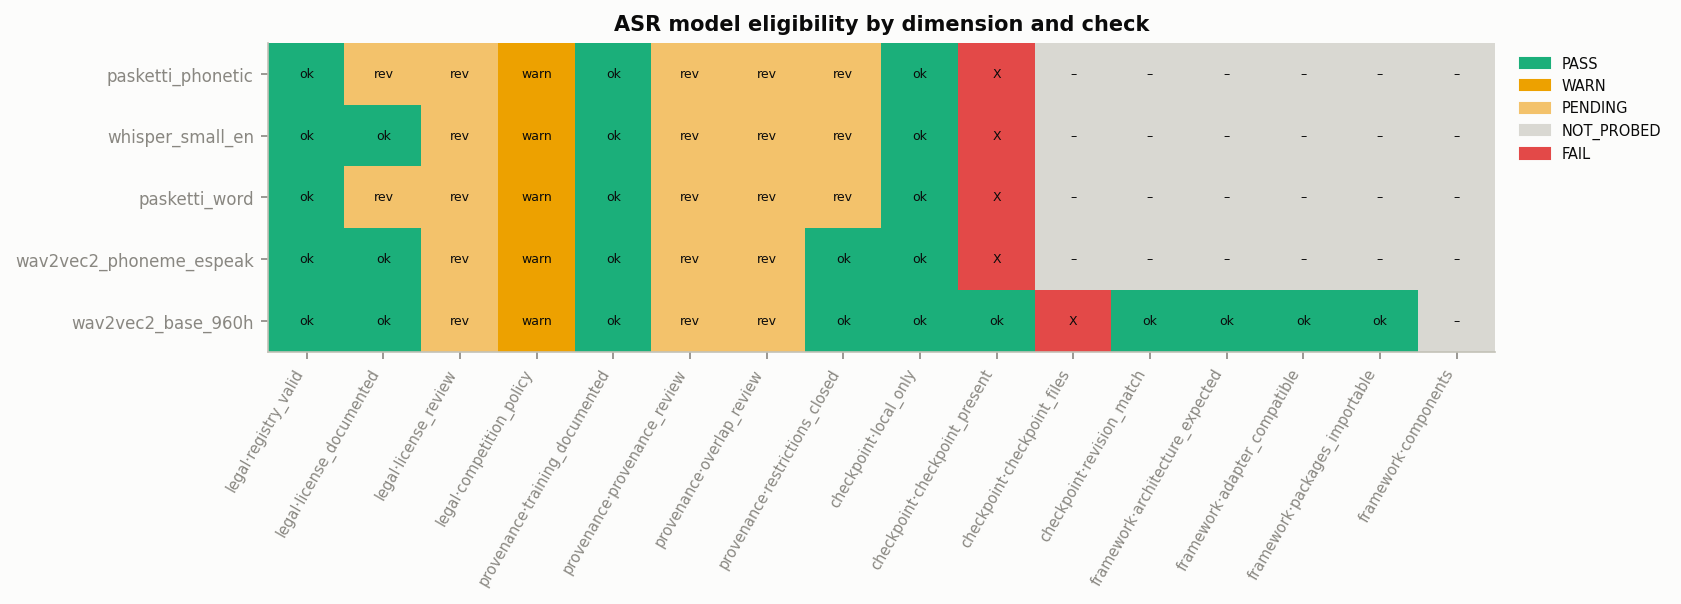

eligibility_matrix_before.png


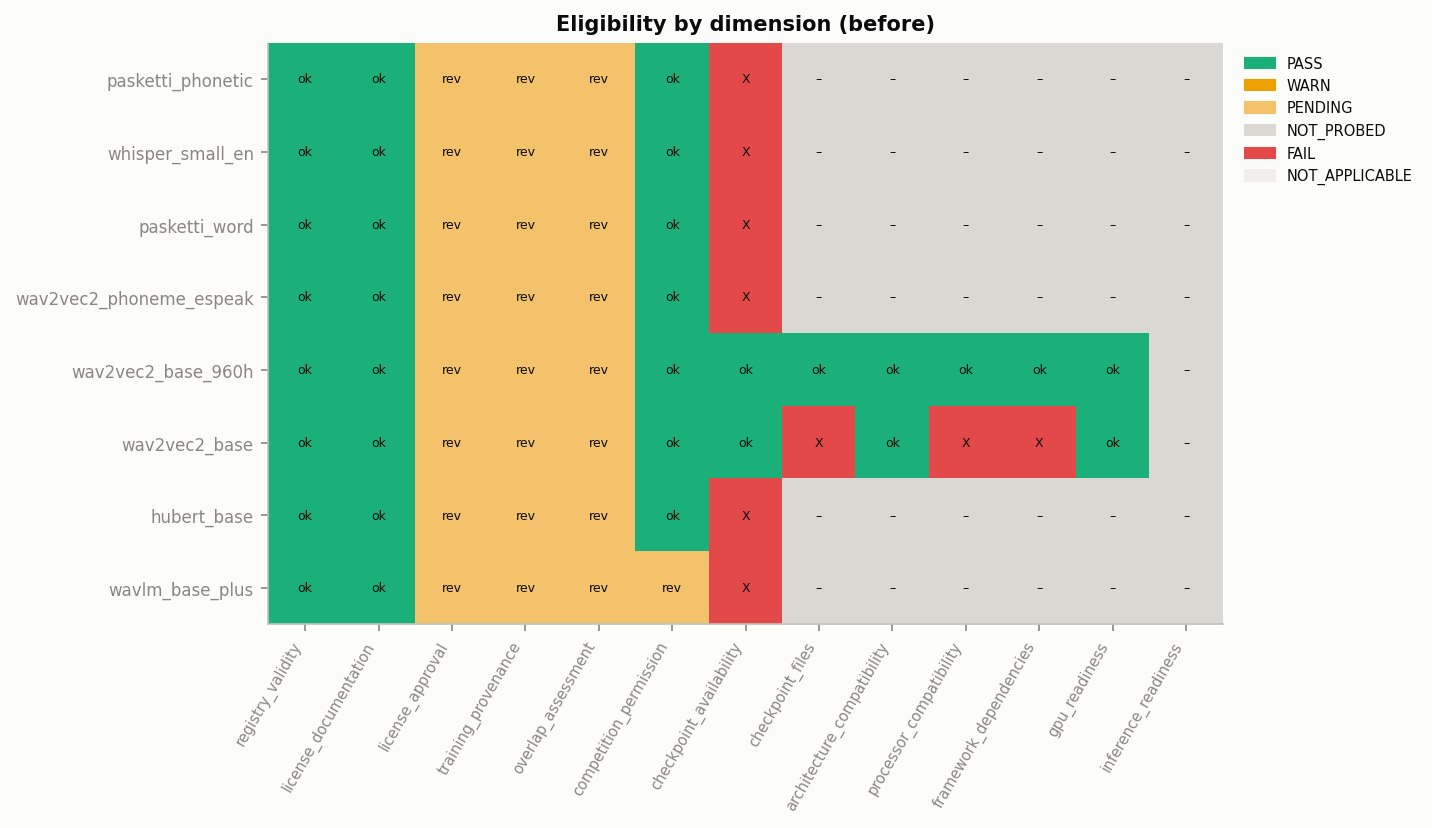

model_readiness_before.png


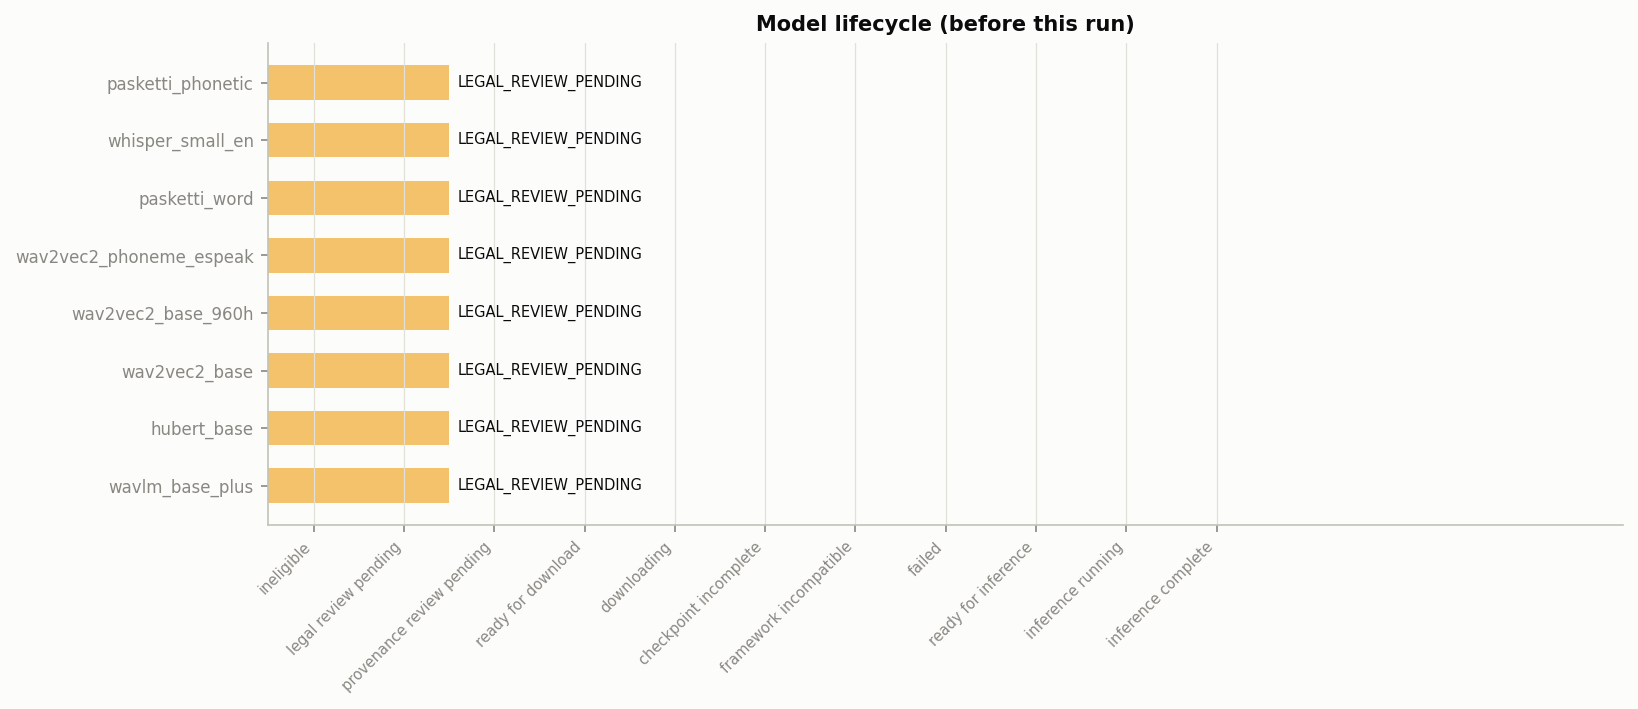

In [14]:
display(nb.execution_state(ctx))
display(nb.coverage_figure(ctx))
safe_tables( "P24", ("not_executed", "model_readiness", "install_results", "smoke_tests", "inference_runs", "throughput",
                       "asr_outputs_inventory", "preferred_models"))
nb.show_figures(ctx, "P24")

## 6. Transcript and phoneme inspection (training clips, accepted outputs only)

In [15]:
try:
    tr = nb.transcripts(ctx, n=8)
    display(tr if tr is not None and not tr.empty else "NO_RESULTS: no validated ASR transcripts")
except (EmptyDataError, FileNotFoundError, ValueError) as exc:
    print("NO_RESULTS: transcription inspection:", exc)
ex = safe_table("P24", "transcription_examples", n=None)
if ex is not None:
    if {"model_key", "task"}.issubset(ex.columns):
        display(ex.groupby(["model_key", "task"], dropna=False).head(3))
    else:
        display(ex.head(12))


no accepted ASR output yet (P24 has not produced real inference)


'NO_RESULTS: no validated ASR transcripts'

[P24] 'transcription_examples': MISSING (P24/transcription_examples not written) | stage outcome: NOT_EXECUTED — eligibility only: no speech model is READY_FOR_INFERENCE (see model_eligibility.csv / required_actions.csv); no inference was run
[P24/transcription_examples] NO_RESULTS


## 7. Phonetic feature engineering (P25)
WER, CER, PER, substitutions / deletions / insertions, expected-text alignment, alignment confidence (GOP), expected-response likelihood,
uncertainty, timing and task features — recognisers with accepted outputs only. Phone features exist only for models that emit phones
(or a verified G2P path); missing outputs stay missing (never imputed as zeros).

In [16]:
run_when_ready("P25", minimum_models=1)


[P25] PLANNED; RUN_PIPELINE=False


In [17]:
safe_tables( "P25", ("not_executed", "asr_output_gate", "feature_tables", "child_vs_general_auc"))
fs = nb.phoneme_feature_summary(ctx)
if fs is not None:
    print("--- phoneme / word / confidence / timing feature coverage")
    display(fs)
val = safe_table("P25", "correctness_validation_auc", n=None)
if val is not None and "auc_oriented" in val:
    display(val.sort_values("auc_oriented", ascending=False).head(30))
nb.show_figures(ctx, "P25", limit=20)    # phoneme confusion matrices, error heatmaps, alignment examples, model comparison

[P25/not_executed]


,stage,status,reason
0,P25,NOT_EXECUTED,needs >= 1 model(s) with real ASR text outputs on ['train']; accepted: none; rejected caches: pasketti_phonetic/trai...


[P25/asr_output_gate]


,model_key,split,origin,output,rows,nonempty_transcripts,nonempty_phones,embedding_rows,failures,has_token_probs_frac,fingerprint,model_version,accepted,reason,revalidated_out,used
0,pasketti_phonetic,train,none,NaN,0,0,0,0,0,NaN,NaN,NaN,False,no _provenance.json,NaN,False
1,pasketti_word,train,none,NaN,0,0,0,0,0,NaN,NaN,NaN,False,no _provenance.json,NaN,False
2,wav2vec2_base_960h,train,none,NaN,0,0,0,0,0,NaN,NaN,NaN,False,no _provenance.json,NaN,False
3,wav2vec2_phoneme_espeak,train,none,NaN,0,0,0,0,0,NaN,NaN,NaN,False,no _provenance.json,NaN,False
4,whisper_small_en,train,none,NaN,0,0,0,0,0,NaN,NaN,NaN,False,no _provenance.json,NaN,False


[P25] 'feature_tables': STALE — written 2026-11-20 23:28, before the last P25 run (not_executed, 2026-11-21T13:17:23); not shown (allow_stale=True to inspect) | stage outcome: NOT_EXECUTED — needs >= 1 model(s) with real ASR text outputs on ['train']; accepted: none; rejected caches: pasketti_phonetic/train (no _provenance.json); pasketti_word/train
[P25/feature_tables] NO_RESULTS
[P25] 'child_vs_general_auc': MISSING (P25/child_vs_general_auc not written) | stage outcome: NOT_EXECUTED — needs >= 1 model(s) with real ASR text outputs on ['train']; accepted: none; rejected caches: pasketti_phonetic/train (no _provenance.json); pasketti_word/train
[P25/child_vs_general_auc] NO_RESULTS
no P25 phonetic features yet
[P25] 'correctness_validation_auc': MISSING (P25/correctness_validation_auc not written) | stage outcome: NOT_EXECUTED — needs >= 1 model(s) with real ASR text outputs on ['train']; accepted: none; rejected caches: pasketti_phonetic/train (no _provenance.json); pasketti_word/tra

## 8. Correct-response experiments (P26)
Among students answering the same item correctly: item-adjusted confidence, hesitation and pronunciation consistency vs outcome,
controlling for screening, item and domain (fold-fitted).

In [18]:
run_when_ready("P26", minimum_models=1)
safe_tables( "P26", ("not_executed", "primary_model_roles", "clip_correctness_increment", "student_incremental_r2",
                       "residual_associations"))
nb.show_figures(ctx, "P26")

[P26] PLANNED; RUN_PIPELINE=False
[P26] 'not_executed': MISSING (P26/not_executed not written)
[P26/not_executed] NO_RESULTS
[P26] 'primary_model_roles': MISSING (P26/primary_model_roles not written)
[P26/primary_model_roles] NO_RESULTS
[P26] 'clip_correctness_increment': MISSING (P26/clip_correctness_increment not written)
[P26/clip_correctness_increment] NO_RESULTS
[P26] 'student_incremental_r2': MISSING (P26/student_incremental_r2 not written)
[P26/student_incremental_r2] NO_RESULTS
[P26] 'residual_associations': MISSING (P26/residual_associations not written)
[P26/residual_associations] NO_RESULTS
[P26] no figures yet


## 9. ASR model disagreement (P27)
General vs child-specific recognition; requires **≥ 2** recognisers with genuinely executed, accepted outputs (otherwise `NOT_EXECUTED`).

In [19]:
run_when_ready("P27", minimum_models=2)
safe_tables( "P27", ("not_executed", "variance_decomposition", "student_disagreement_consistency", "disagreement_by_task",
                       "high_uncertainty_by_task"))
nb.show_figures(ctx, "P27")

[P27] PLANNED; RUN_PIPELINE=False
[P27] 'not_executed': MISSING (P27/not_executed not written)
[P27/not_executed] NO_RESULTS
[P27] 'variance_decomposition': MISSING (P27/variance_decomposition not written)
[P27/variance_decomposition] NO_RESULTS
[P27] 'student_disagreement_consistency': MISSING (P27/student_disagreement_consistency not written)
[P27/student_disagreement_consistency] NO_RESULTS
[P27] 'disagreement_by_task': MISSING (P27/disagreement_by_task not written)
[P27/disagreement_by_task] NO_RESULTS
[P27] 'high_uncertainty_by_task': MISSING (P27/high_uncertainty_by_task not written)
[P27/high_uncertainty_by_task] NO_RESULTS
[P27] no figures yet


## 10. Frozen speech embeddings
Pooled, frozen embeddings over valid frames only: recogniser encoders and the self-supervised encoders (wav2vec2-base, HuBERT-base,
WavLM-base-plus; layers 6 and 12). Group-norm encoders run one clip per forward pass (they ignore attention masks).

In [20]:
emb = nb.embedding_summary(ctx)
display(emb if not emb.empty else "NO_RESULTS: no accepted embeddings yet")

'NO_RESULTS: no accepted embeddings yet'

## 11. Compact phonetic representations (P28)
Select / PCA / PLS / RRR (+MIL) at 5–100 features, fitted inside each fold; includes the frozen-encoder families ASR13 / ASRF_*.

In [21]:
run_when_ready("P28", minimum_models=1)
safe_tables( "P28", ("not_executed", "family_availability", "exploratory_best_config", "fallback_share_by_family"))
rr = safe_table("P28", "representation_results", n=None)
if rr is not None:
    display(rr.sort_values("delta_r2", ascending=False).head(25) if "delta_r2" in rr else rr.head(25))
nb.show_figures(ctx, "P28")

[P28] PLANNED; RUN_PIPELINE=False
[P28] 'not_executed': MISSING (P28/not_executed not written)
[P28/not_executed] NO_RESULTS
[P28] 'family_availability': MISSING (P28/family_availability not written)
[P28/family_availability] NO_RESULTS
[P28] 'exploratory_best_config': MISSING (P28/exploratory_best_config not written)
[P28/exploratory_best_config] NO_RESULTS
[P28] 'fallback_share_by_family': MISSING (P28/fallback_share_by_family not written)
[P28/fallback_share_by_family] NO_RESULTS
[P28] 'representation_results': MISSING (P28/representation_results not written)
[P28/representation_results] NO_RESULTS
[P28] no figures yet


## 12. Reading prediction and ablations (P29)
Same student-disjoint folds as the GAM baseline (frozen validation registry), nested transformations, paired bootstrap CIs, FDR,
negative controls, stability, confounding, transfer schemes and the **NO_PASKETTI overlap sensitivity**. Every row carries a
`result_class`: `GENUINE_GAIN`, `GENUINE_NEGATIVE`, `NO_DETECTABLE_EFFECT`, `BASELINE_FALLBACK` (a fold fell back to the baseline — its
ΔR² says nothing about the features), `NOT_REPORTABLE`, `UNDETERMINED`.

In [22]:
run_when_ready("P29", minimum_models=1)
safe_tables( "P29", ("not_executed", "baseline_reference_check", "baseline_by_scheme", "result_classes", "validated_families"))
ab = safe_table("P29", "ablation_results", n=None)
if ab is not None:
    cols = [c for c in ("experiment", "name", "scheme", "fusion", "r2_mean", "delta_r2", "delta_ci_low", "delta_ci_high", "q",
                        "fallback_folds", "result_class") if c in ab]
    display(ab[cols].sort_values("delta_r2", ascending=False).head(40))
safe_tables( "P29", ("transfer_robustness", "family_stability", "confounding", "overlap_sensitivity"))
nb.show_figures(ctx, "P29")

[P29] PLANNED; RUN_PIPELINE=False
[P29] 'not_executed': MISSING (P29/not_executed not written)
[P29/not_executed] NO_RESULTS
[P29] 'baseline_reference_check': MISSING (P29/baseline_reference_check not written)
[P29/baseline_reference_check] NO_RESULTS
[P29] 'baseline_by_scheme': MISSING (P29/baseline_by_scheme not written)
[P29/baseline_by_scheme] NO_RESULTS
[P29] 'result_classes': MISSING (P29/result_classes not written)
[P29/result_classes] NO_RESULTS
[P29] 'validated_families': MISSING (P29/validated_families not written)
[P29/validated_families] NO_RESULTS
[P29] 'ablation_results': MISSING (P29/ablation_results not written)
[P29/ablation_results] NO_RESULTS
[P29] 'transfer_robustness': MISSING (P29/transfer_robustness not written)
[P29/transfer_robustness] NO_RESULTS
[P29] 'family_stability': MISSING (P29/family_stability not written)
[P29/family_stability] NO_RESULTS
[P29] 'confounding': MISSING (P29/confounding not written)
[P29/confounding] NO_RESULTS
[P29] 'overlap_sensitivity'

## 13. Scientific plots
Model readiness, inference throughput, phoneme confusion, expected-vs-recognised alignments, correctness confidence, residual
correlations, ablations and incremental R² (each saved with its data table).

=== P24
eligibility_matrix.png


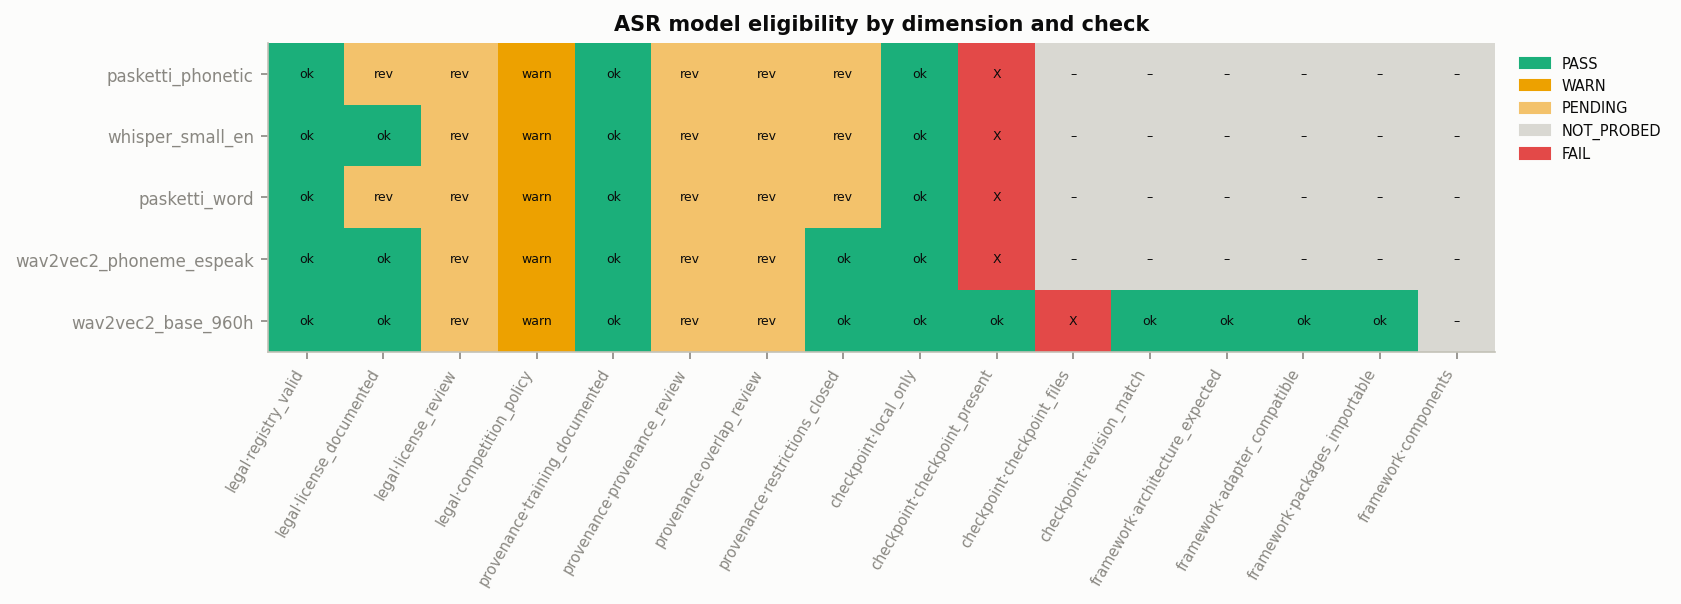

eligibility_matrix_before.png


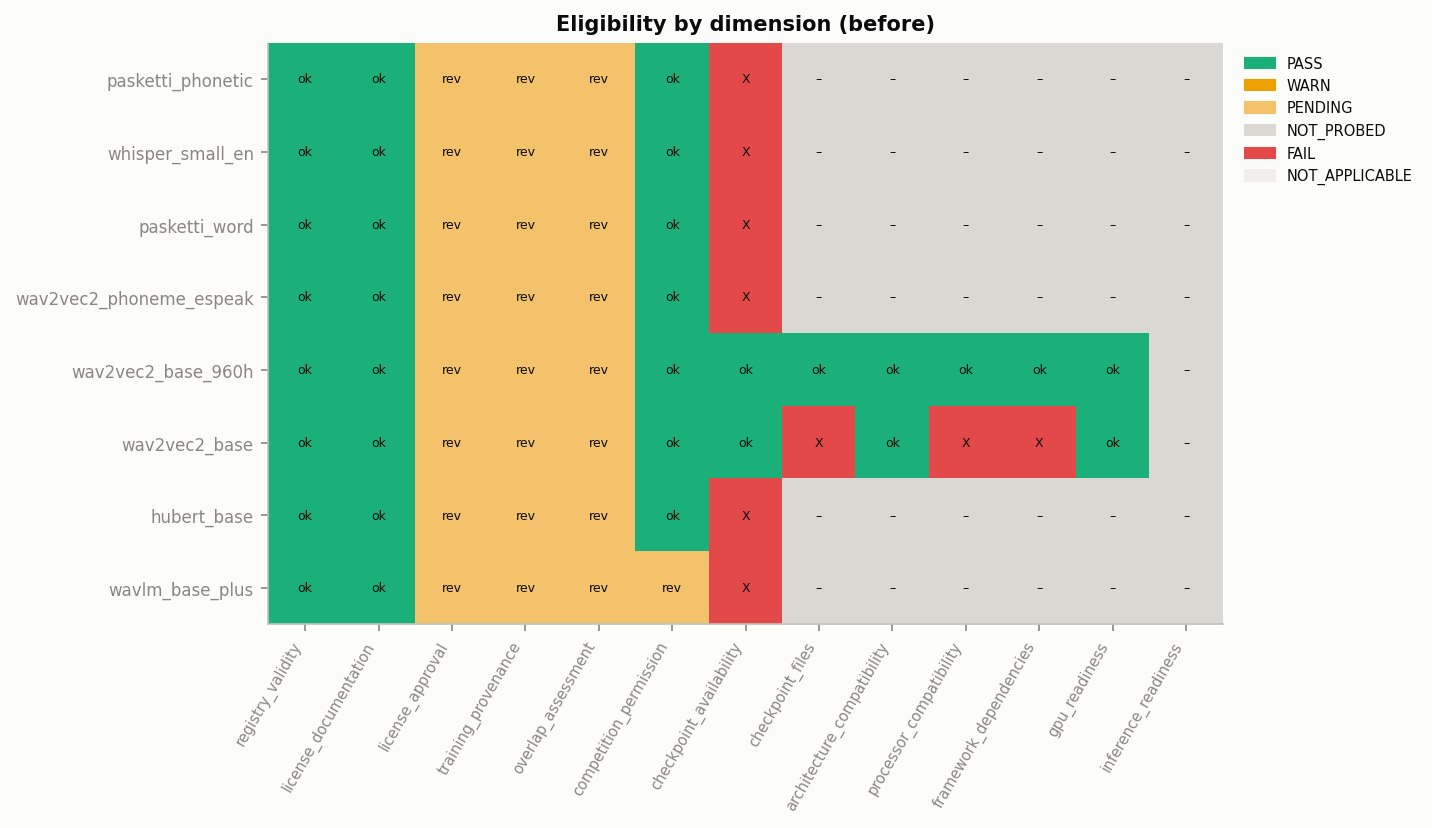

model_readiness_before.png


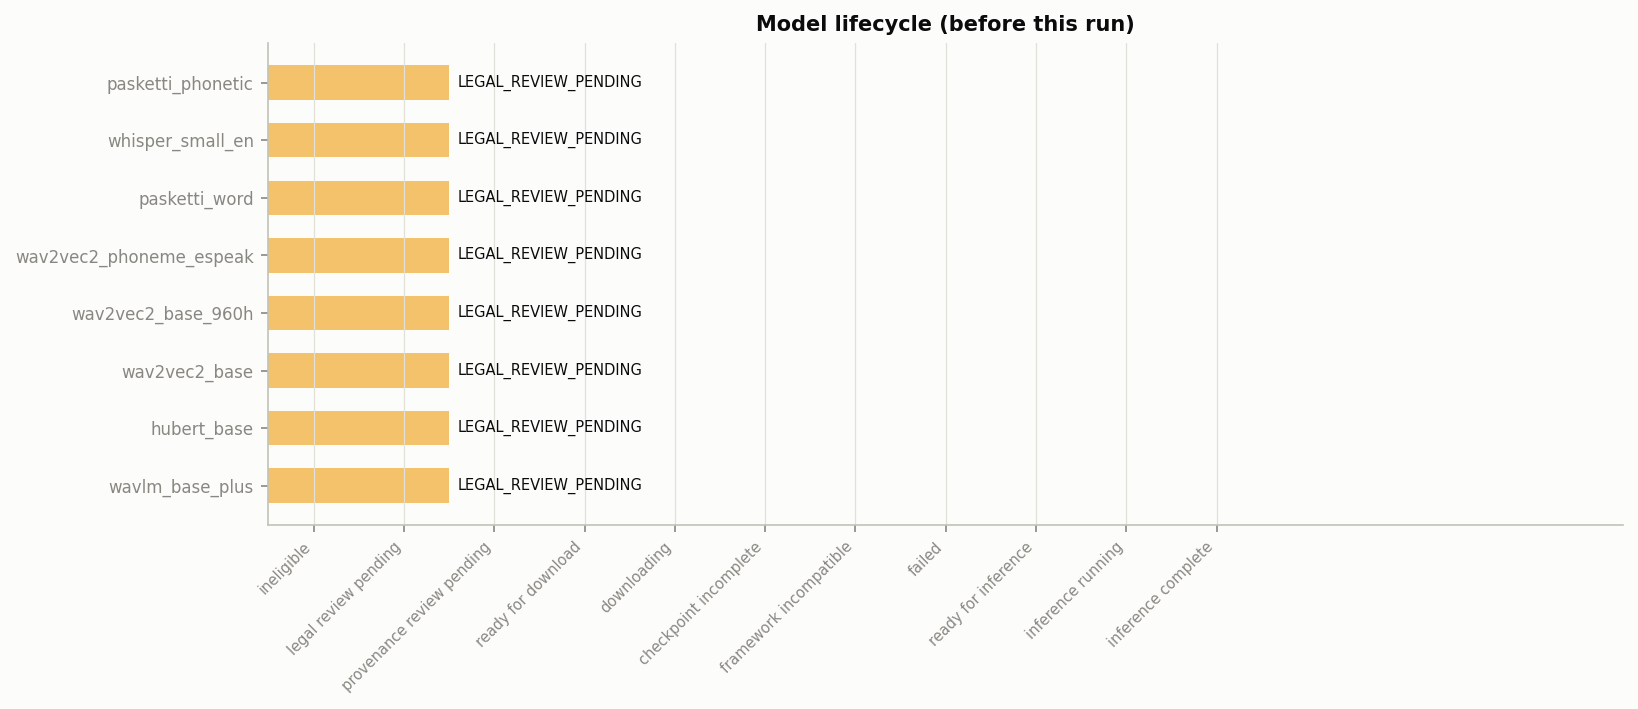

=== P25
[P25] no figures yet
=== P26
[P26] no figures yet
=== P27
[P27] no figures yet
=== P28
[P28] no figures yet
=== P29
[P29] no figures yet


In [23]:
for s in ("P24", "P25", "P26", "P27", "P28", "P29"):
    print(f"=== {s}")
    nb.show_figures(ctx, s, limit=24)

## 14. Champion selection
The GAM (R² ≈ 0.2153) stays champion unless a reportable V3 model has ΔR² CI > 0, q < α on the primary scheme and ΔR² > 0 under
school-grouped CV. A `BASELINE_FALLBACK` row can never become champion.

In [24]:
safe_tables( "P29", ("champion_comparison", "champion_subgroups", "baseline_reference_check", "validated_families"))

[P29] 'champion_comparison': MISSING (P29/champion_comparison not written)
[P29/champion_comparison] NO_RESULTS
[P29] 'champion_subgroups': MISSING (P29/champion_subgroups not written)
[P29/champion_subgroups] NO_RESULTS
[P29] 'baseline_reference_check': MISSING (P29/baseline_reference_check not written)
[P29/baseline_reference_check] NO_RESULTS
[P29] 'validated_families': MISSING (P29/validated_families not written)
[P29/validated_families] NO_RESULTS


## 15. Final reporting
Hypothesis statuses come from runtime tables only; the HTML report is built from saved artefacts.

In [25]:
from wildspeech.v3.registry import v3_registries

reg = v3_registries(ctx)
h = reg.hypotheses.frame()
display(h[[c for c in ("hypothesis_id", "statement", "status", "evidence_tier", "evidence", "effect", "ci_low", "ci_high", "q_value") if c in h]])
e = reg.experiments.frame()
if not e.empty and {"stage", "status"} <= set(e.columns):
    display(e.groupby(["stage", "status"]).size().rename("n").reset_index())
display(nb.stage_readiness(ctx))

,hypothesis_id,statement,status,evidence_tier,evidence,effect,ci_low,ci_high,q_value
0,V3H01,At least one V2 family whose reported ΔR² was exactly 0 was a silent fallback to the baseline (residual shrinkage al...,supported,confirmatory,"6/9 audited V2 specs were baseline fallbacks: P21_ALL_RESIDUAL_RIDGE,P21_BUDGET_ALL_100,P21_SINGLE_CPX,P21_SINGLE_HA...",None,NaN,NaN,NaN
1,V3H02,"The V1 TASK_ENSEMBLE failure (R² << 0) is caused by unbounded stacking weights / extreme per-task predictions, and t...",supported,confirmatory,"extreme_frac V1=0.0006, repaired=0.0000; mean weight sum V1=1.11",1706.210687444906,NaN,NaN,NaN
2,V3H03,A child-specific recogniser agrees with official item correctness better than a general-purpose recogniser (clip AUR...,proposed,None,None,None,NaN,NaN,NaN
3,V3H04,"Among CORRECT responses, item-adjusted phonetic confidence is associated with the screening-model residual of the en...",proposed,None,None,None,NaN,NaN,NaN
4,V3H05,Phonetic features improve clip-correctness prediction beyond metadata-only and temporal-only models.,proposed,None,None,None,NaN,NaN,NaN
5,V3H06,Recogniser disagreement is explained more by item difficulty and recording conditions than by stable student traits.,proposed,None,None,None,NaN,NaN,NaN
6,V3H07,A compact phonetic representation with <= 20 added features gives the largest incremental R² over the tabular GAM.,proposed,None,None,None,NaN,NaN,NaN
7,V3H08,"At least one validated phonetic family adds incremental R² over the best tabular GAM (paired bootstrap CI > 0, FDR, ...",proposed,None,None,None,NaN,NaN,NaN
8,V3H09,Correct-response-only features carry incremental information beyond official correctness counts.,proposed,None,None,None,NaN,NaN,NaN
9,V3H10,Phonetic incremental value survives sample-rate and instrument transfer (ΔR² > 0 in transfer schemes).,proposed,None,None,None,NaN,NaN,NaN


,stage,status,n
0,P23,fallback_baseline,19
1,P23,ok,10
2,P23,partial_fallback,2


,stage,enabled,protected,last_status,finished,outcome,results_are_real,inputs,inputs_ready,up_to_date,note
0,P23,True,True,completed,2026-11-20T23:28:29,,True,V1/V2 artefacts,True,True,
1,P24,True,False,not_executed,2026-11-21T13:43:59,ELIGIBILITY_ONLY,False,eligible models (see model_readiness),None,None,eligibility only: no speech model is READY_FOR_INFERENCE (see model_eligibility.csv / required_actions.csv); no infe...
2,P25,True,False,not_executed,2026-11-21T13:17:23,NOT_EXECUTED,False,0/1 accepted ASR model(s): none,False,None,needs >= 1 model(s) with real ASR text outputs on ['train']; accepted: none; rejected caches: pasketti_phonetic/trai...
3,P26,True,False,blocked,2026-11-21T13:17:22,,False,0/1 accepted ASR model(s): none,False,None,waiting for ['P25']
4,P27,True,False,blocked,2026-11-21T13:17:23,,False,0/2 accepted ASR model(s): none,False,None,waiting for ['P25']
5,P28,True,False,blocked,2026-11-21T13:17:23,,False,0/1 accepted ASR model(s): none,False,None,waiting for ['P25']
6,P29,True,False,blocked,2026-11-21T13:17:23,,False,0/1 accepted ASR model(s): none,False,None,waiting for ['P28']


In [26]:
if RUN_PIPELINE:
    print("report:", nb.report(ctx))
else:
    print("RUN_PIPELINE is False -> report not rebuilt (python -m wildspeech v3-report)")

RUN_PIPELINE is False -> report not rebuilt (python -m wildspeech v3-report)
